In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import os
import json
import scvi
import seaborn as sns
import matplotlib.cm as cm


from utils import preprocessing
from utils import label_mapping_utils as lmu

BASE_PATH = os.getenv("BASE_PATH_FOR_SAVING")

ADATA =  f'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned.h5ad'


SAMPLE_VARIABLE = "DONOR"
CONDITION_VARIABLE = "Status"
LOW_QUALITY_LABEL = "-Low_quality"


In [ ]:
adata = sc.read_h5ad(ADATA, backed="r")
adata = adata[adata.obs["experiment"] == "village"].to_memory().copy()
print(adata)

In [ ]:
# Calculate qc
    # attention: need raw counts in .X
adata.var["mt"] = adata.var.gene_symbol.str.startswith("MT-") # mitochondrial genes, ATTNETION: the names are in "gene_symbol"
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)

In [ ]:
# Preprocess
leiden_cluster_names = lmu.preprocess_common_pipeline(adata, leiden_name="_all_cells", integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

In [ ]:
adata.obs["Subclass_name"].value_counts()

freq_subclass_neurons = [
                'STR D1 MSN', 'STR D2 MSN', 'STR Hybrid MSN',
                'CN ST18 GABA', 
                'STR SST-CHODL GABA', 
                #'CN VIP GABA', 'CN Cholinergic GABA', 'F GABA', 'ACx MEIS2 GABA', 
                'OT Granular GABA']

freq_group_neurons = adata.obs[adata.obs["Subclass_name"].isin(freq_subclass_neurons)]["Group_name"].cat.remove_unused_categories().value_counts().index.values
freq_group_neurons

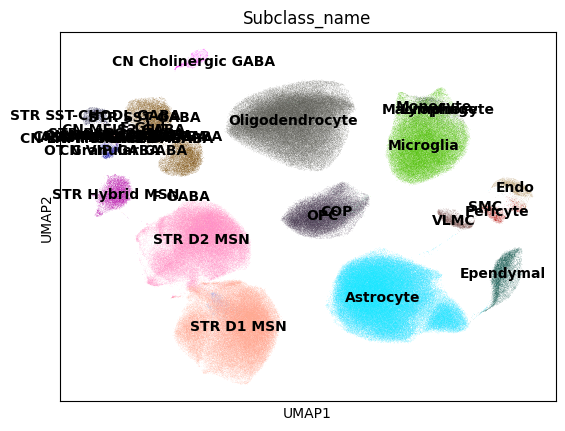

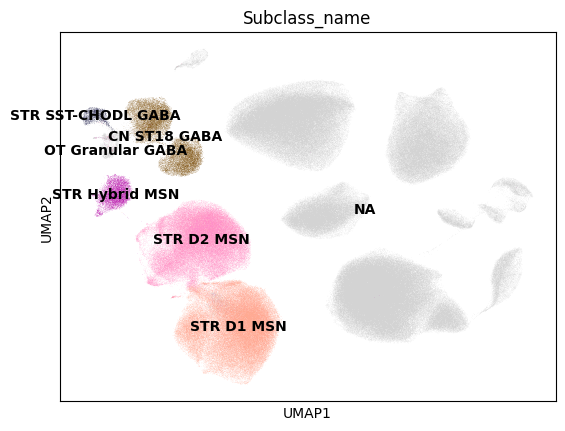

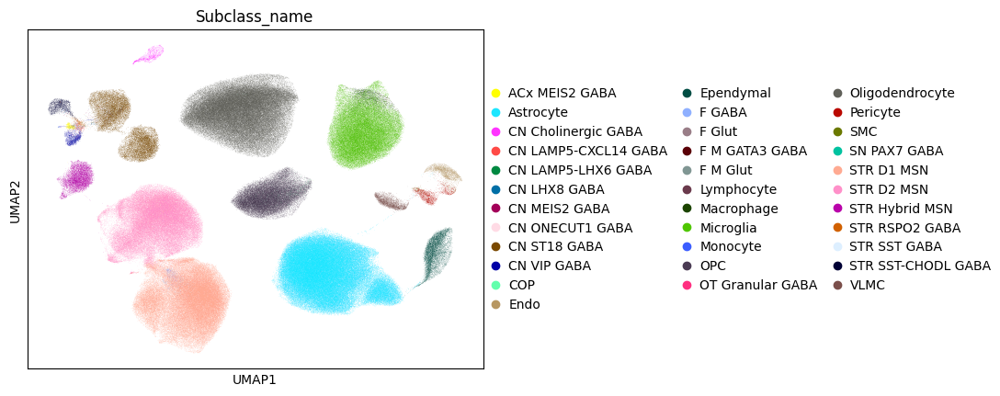

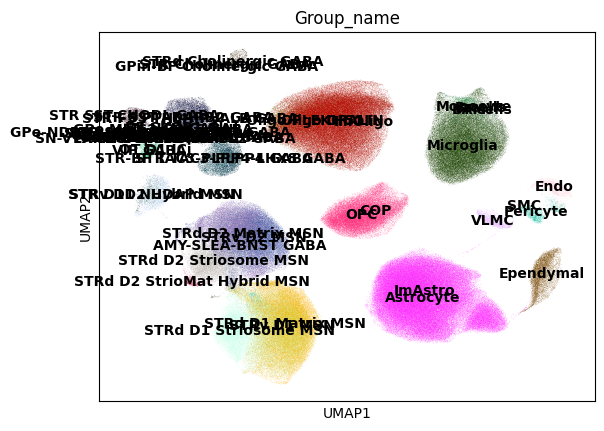

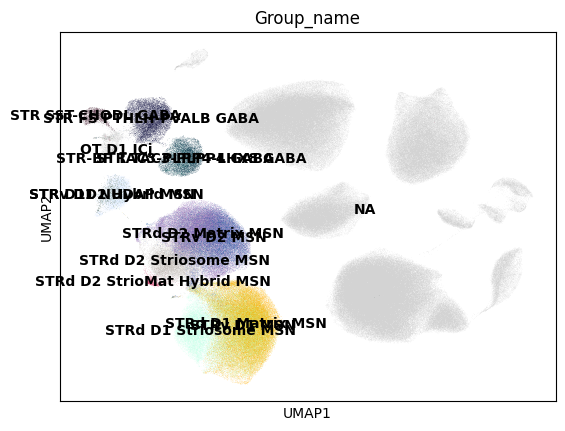

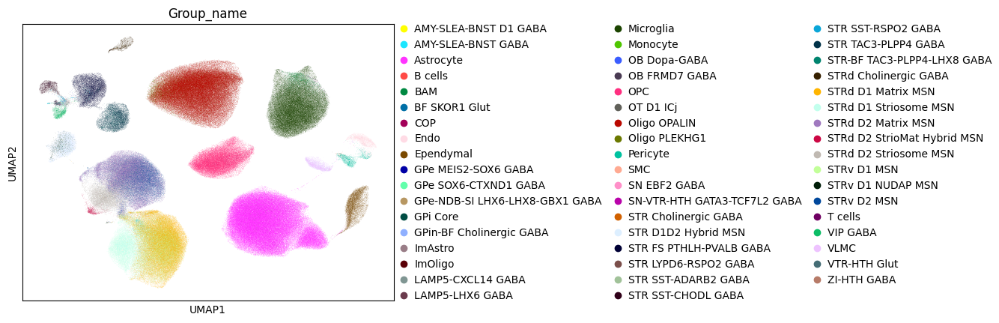

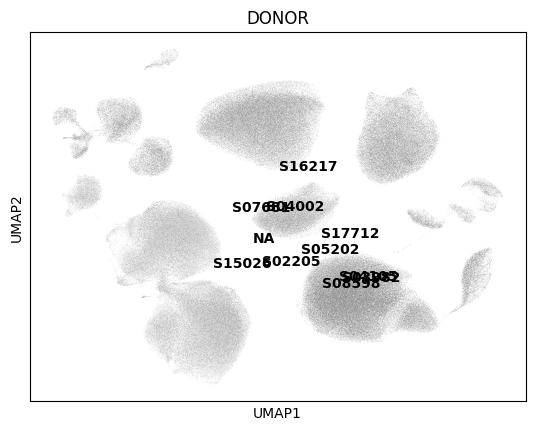

In [8]:
sc.pl.umap(adata, color=["Subclass_name"], legend_loc="on data")
sc.pl.umap(adata, color=["Subclass_name"], legend_loc="on data", groups=freq_subclass_neurons)
sc.pl.umap(adata, color=["Subclass_name"])

sc.pl.umap(adata, color=["Group_name"], legend_loc="on data")
sc.pl.umap(adata, color=["Group_name"], legend_loc="on data", groups=freq_group_neurons)
sc.pl.umap(adata, color=["Group_name"])



sc.pl.umap(adata, color=[SAMPLE_VARIABLE], groups=adata.obs[SAMPLE_VARIABLE].value_counts().index[:10].values,  legend_loc="on data")


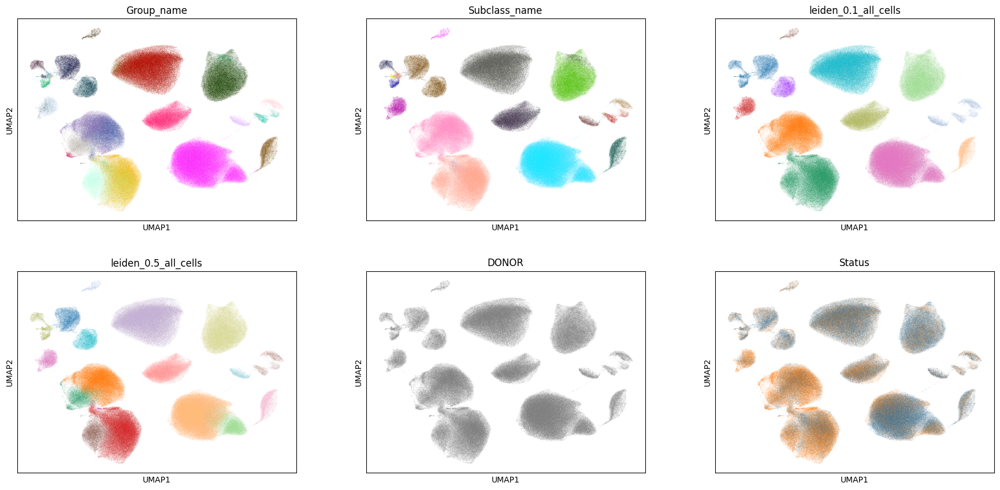

In [9]:
sc.pl.umap(adata, color=["Group_name", "Subclass_name", leiden_cluster_names[0], leiden_cluster_names[1], SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=3, legend_loc=None)

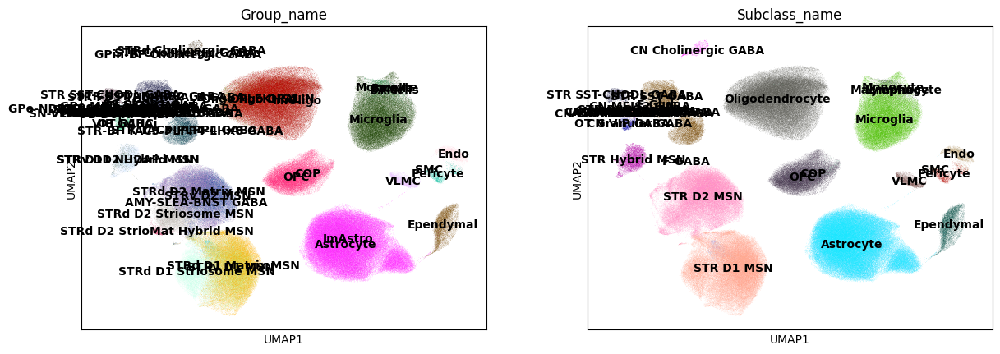

In [10]:
sc.pl.umap(adata, color=["Group_name", "Subclass_name"], ncols=3, legend_loc="on data")

# Glia: Oligo

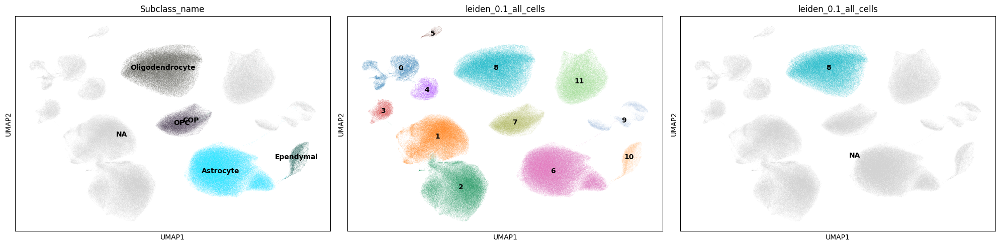

In [5]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["8"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_oligo"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

In [6]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-28 17:02:12,811 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 17:02:12 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 17:02:12,813 - harmonypy - INFO -   Parameters:
2026-08-28 17:02:12 | [INFO]   Parameters:
2026-08-28 17:02:12,814 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 17:02:12 | [INFO]     max_iter_harmony: 30
2026-08-28 17:02:12,814 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 17:02:12 | [INFO]     max_iter_kmeans: 20
2026-08-28 17:02:12,815 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 17:02:12 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 17:02:12,816 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 17:02:12 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 17:02:12,817 - harmonypy - INFO -     nclust: 100
2026-08-28 17:02:12 | [INFO]     nclust: 100
2026-08-28 17:02:12,818 - harmonypy - INFO -     block_size: 0.05
2026-08-28 17:02:12 | [INFO]     block_size: 0.05
2026-08-28 17:02:12,820 - harm

Running Harmony batch correction...


2026-08-28 17:02:13,577 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-28 17:02:13 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-08-28 17:02:15,839 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 17:02:15 | [INFO] KMeans initialization complete.
2026-08-28 17:02:16,220 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 17:02:16 | [INFO] Iteration 1 of 30
2026-08-28 17:02:19,205 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 17:02:19 | [INFO] Iteration 2 of 30
2026-08-28 17:02:21,906 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 17:02:21 | [INFO] Iteration 3 of 30
2026-08-28 17:02:24,425 - harmonypy - INFO - Converged after 3 iterations
2026-08-28 17:02:24 | [INFO] Converged after 3 iterations


Z_corr shape: (107690, 50), n_obs: 107690
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


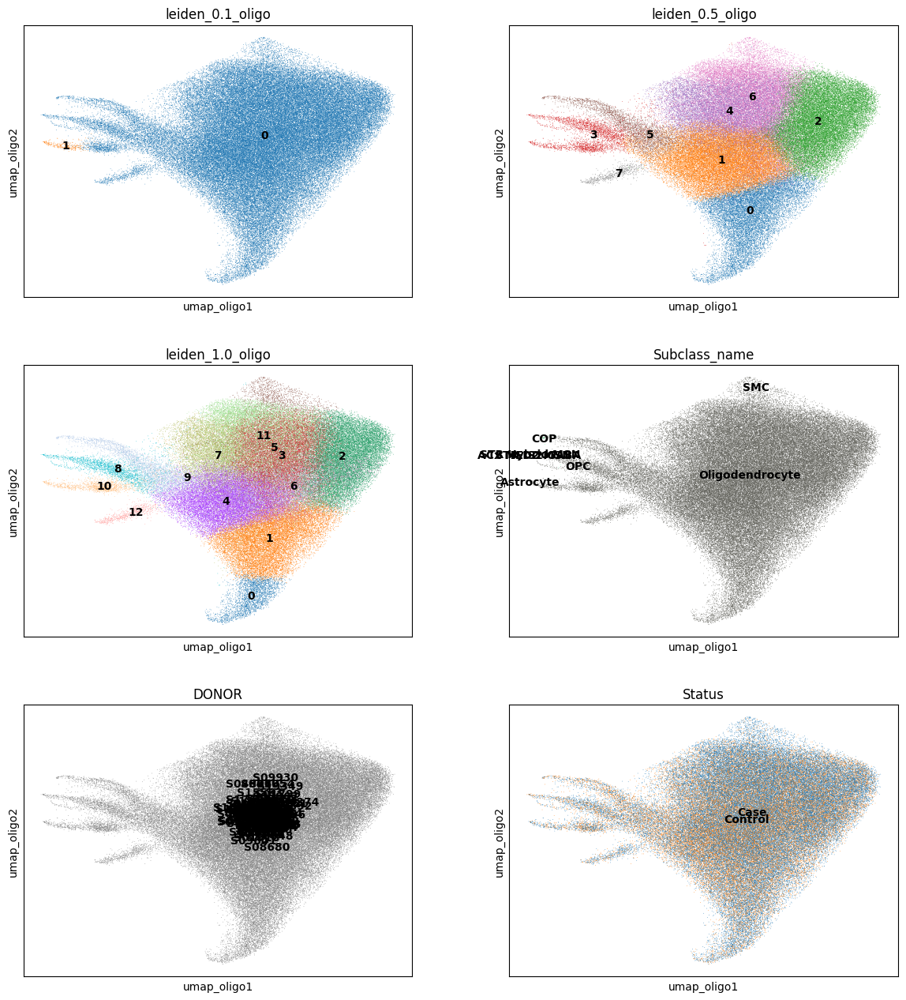

In [7]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, legend_loc="on data")

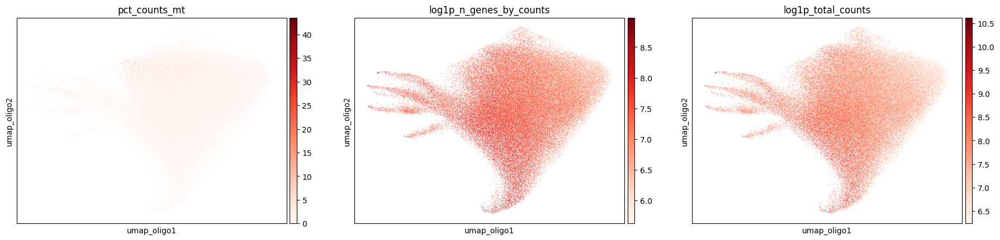

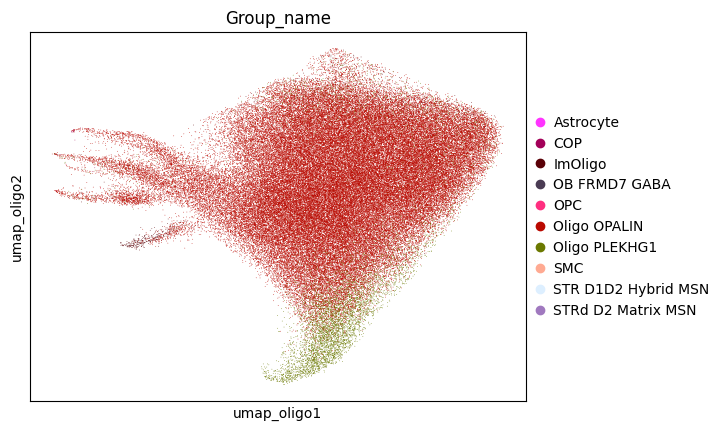

In [8]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"])

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

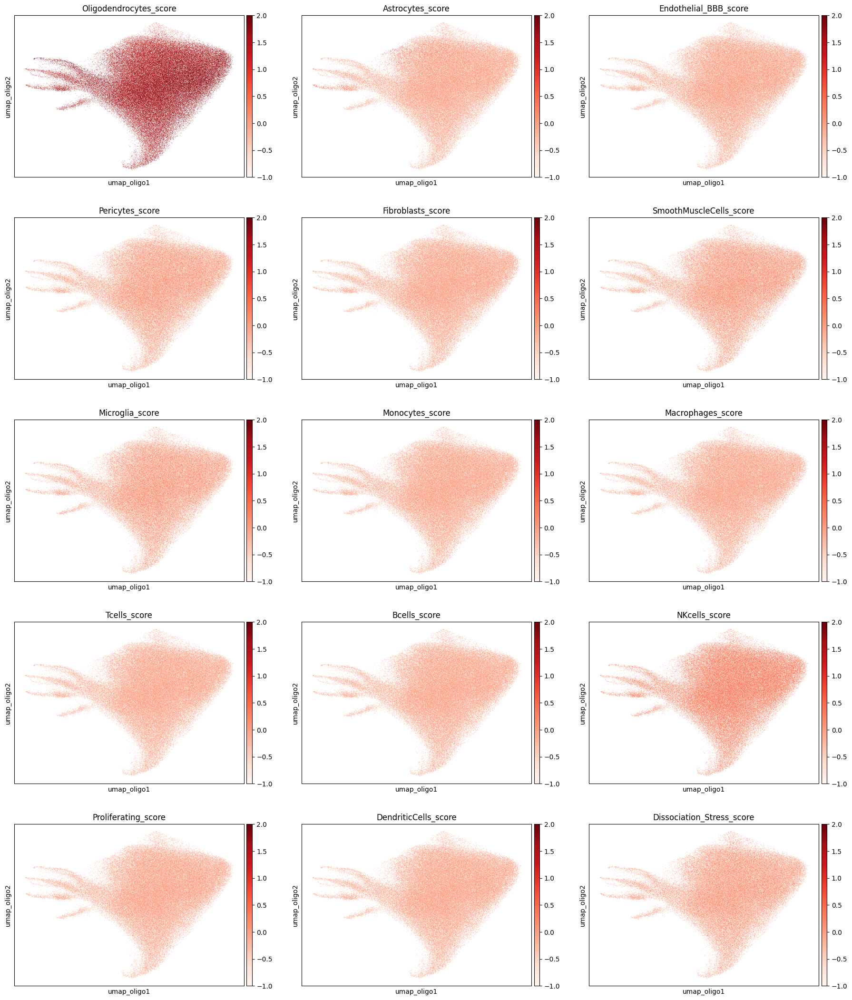

In [11]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


In [12]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"


In [13]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             groups=["8", "9", "10", "12"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 8:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185774,36.250416,3.354990,9.787920e-288,3.615951e-283,KCNIP4
1,ENSG00000224078,34.412537,1.611893,1.637523e-259,3.024750e-255,SNHG14
2,ENSG00000138814,34.225807,1.690257,9.992806e-257,1.230547e-252,PPP3CA
3,ENSG00000172995,30.880108,1.779875,2.209576e-209,2.040709e-205,ARPP21
4,ENSG00000070961,29.133606,2.617609,1.347789e-186,9.958273e-183,ATP2B1
5,ENSG00000183117,27.482790,4.763800,2.819560e-166,1.736050e-162,CSMD1
6,ENSG00000112137,27.124086,3.405904,5.120220e-162,2.702233e-158,PHACTR1
7,ENSG00000198668,23.146742,1.211820,1.567886e-118,7.240300e-115,CALM1
8,ENSG00000069667,22.682314,1.934476,6.697276e-114,2.749083e-110,RORA
9,ENSG00000198626,21.359900,1.860856,3.154895e-101,1.165513e-97,RYR2


Cluster 9:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000139915,75.712715,3.254452,0.000000e+00,0.000000e+00,MDGA2
1,ENSG00000018236,56.912609,4.235720,0.000000e+00,0.000000e+00,CNTN1
2,ENSG00000178568,53.852303,1.004037,0.000000e+00,0.000000e+00,ERBB4
3,ENSG00000164418,48.869377,4.273129,0.000000e+00,0.000000e+00,GRIK2
4,ENSG00000073910,47.977161,2.117429,0.000000e+00,0.000000e+00,FRY
5,ENSG00000169760,44.064743,0.911800,0.000000e+00,0.000000e+00,NLGN1
6,ENSG00000105894,42.601101,1.460179,0.000000e+00,0.000000e+00,PTN
7,ENSG00000197430,41.207546,1.142867,0.000000e+00,0.000000e+00,OPALIN
8,ENSG00000183783,36.593063,1.293232,3.687494e-293,1.362271e-289,KCTD8
9,ENSG00000185565,35.910347,0.741265,2.106318e-282,7.073972e-279,LSAMP


Cluster 10:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000175497,29.034575,4.117842,2.409710e-185,8.902193e-181,DPP10
1,ENSG00000095637,24.433855,3.636108,7.471980e-132,1.380187e-127,SORBS1
2,ENSG00000069667,24.279833,2.598735,3.202121e-130,3.943198e-126,RORA
3,ENSG00000179399,23.998825,3.310830,2.860395e-127,2.641789e-123,GPC5
4,ENSG00000154217,23.045195,5.427630,1.643486e-117,1.214306e-113,PITPNC1
5,ENSG00000185737,21.851461,5.721584,7.528537e-106,4.635446e-102,NRG3
6,ENSG00000179915,19.023809,3.334015,1.083183e-80,5.716577e-77,NRXN1
7,ENSG00000120885,18.759308,2.069611,1.625036e-78,7.504212e-75,CLU
8,ENSG00000134769,18.138647,1.670573,1.578700e-73,6.480213e-70,DTNA
9,ENSG00000066032,17.917494,1.468387,8.612102e-72,3.181569e-68,CTNNA2


Cluster 12:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000148655,22.614254,4.557695,3.137929e-113,1.159245e-108,LRMDA
1,ENSG00000151474,17.513140,1.855293,1.137427e-68,2.100997e-64,FRMD4A
2,ENSG00000081189,16.309227,4.708537,8.485943e-60,1.044987e-55,MEF2C
3,ENSG00000107099,15.653774,6.252869,3.130857e-55,2.891582e-51,DOCK8
4,ENSG00000073849,14.998577,5.782055,7.501068e-51,5.542239e-47,ST6GAL1
5,ENSG00000182601,14.977240,5.185593,1.034242e-50,6.368001e-47,HS3ST4
6,ENSG00000138639,13.704586,1.751882,9.530921e-43,4.763531e-39,ARHGAP24
7,ENSG00000171310,13.698844,4.795484,1.031542e-42,4.763531e-39,CHST11
8,ENSG00000159216,12.907787,3.619052,4.068251e-38,1.669926e-34,RUNX1
9,ENSG00000145819,12.220924,3.947208,2.403357e-34,8.878722e-31,ARHGAP26


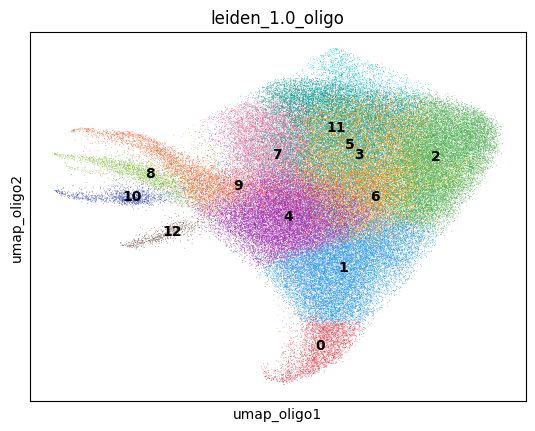

In [10]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=ADATA_NN_LEIDEN_COL_FOR_MAPPING, palette=lmu.custom_palette, legend_loc="on data")


ct_for_deg
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
Patch_D1                    19034
Patch_D2                    14060
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
-Low_quality                 7535
eMSN_D1D2                    7344
STR SST-CHODL GABA           1991
VIP GABA                     1771
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
non-MSN                       881
ACx MEIS2 GABA                651
STR RSPO2 GABA                530
-fake_phase_D                 513
LAMP5 GABA                    357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


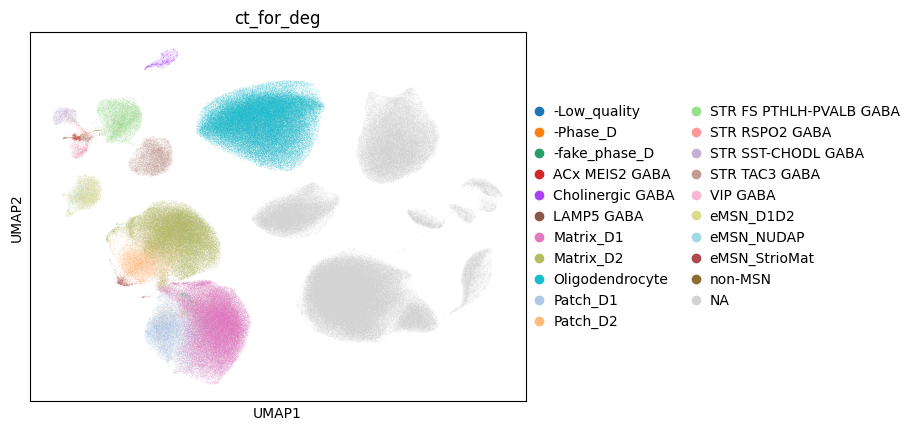

... storing 'tmp_label' as categorical


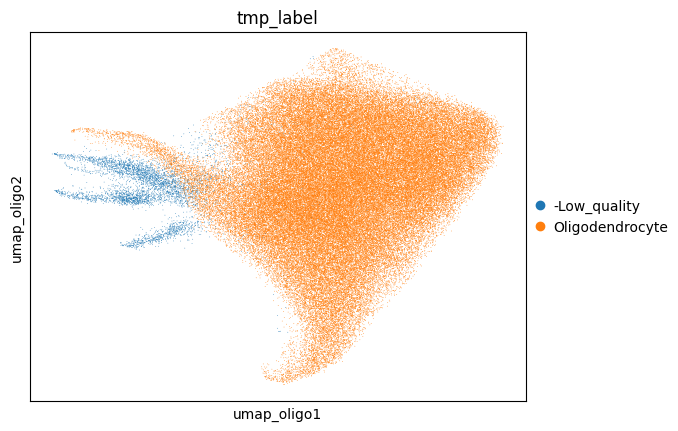

In [15]:
# For Oligo: leave all as Oligo

mapping_dict = {
    "8": LOW_QUALITY_LABEL,
    "10": LOW_QUALITY_LABEL,
    "12": LOW_QUALITY_LABEL,

    # Oligodendrocyte all the rest

    # INGORE cop!
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("Oligodendrocyte")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [16]:
del adata_nn

# Glia: OPC

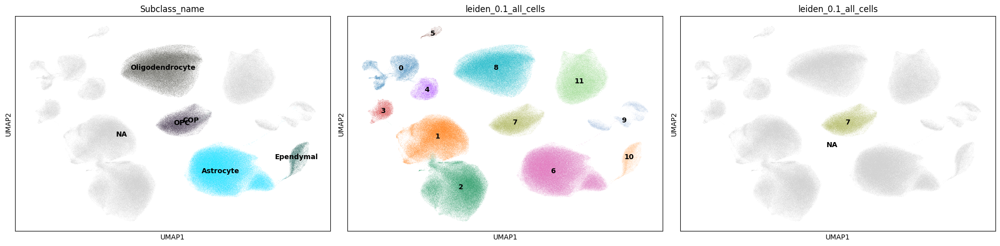

In [18]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["7"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_OPC"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-28 17:36:09,304 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 17:36:09 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 17:36:09,306 - harmonypy - INFO -   Parameters:
2026-08-28 17:36:09 | [INFO]   Parameters:
2026-08-28 17:36:09,307 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 17:36:09 | [INFO]     max_iter_harmony: 30
2026-08-28 17:36:09,307 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 17:36:09 | [INFO]     max_iter_kmeans: 20
2026-08-28 17:36:09,308 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 17:36:09 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 17:36:09,309 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 17:36:09 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 17:36:09,310 - harmonypy - INFO -     nclust: 100
2026-08-28 17:36:09 | [INFO]     nclust: 100
2026-08-28 17:36:09,311 - harmonypy - INFO -     block_size: 0.05
2026-08-28 17:36:09 | [INFO]     block_size: 0.05
2026-08-28 17:36:09,312 - harm

Running Harmony batch correction...


2026-08-28 17:36:10,280 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 17:36:10 | [INFO] KMeans initialization complete.
2026-08-28 17:36:10,286 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 17:36:10 | [INFO] Iteration 1 of 30
2026-08-28 17:36:13,052 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 17:36:13 | [INFO] Iteration 2 of 30
2026-08-28 17:36:15,636 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 17:36:15 | [INFO] Iteration 3 of 30
2026-08-28 17:36:18,145 - harmonypy - INFO - Converged after 3 iterations
2026-08-28 17:36:18 | [INFO] Converged after 3 iterations


Z_corr shape: (37086, 50), n_obs: 37086
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


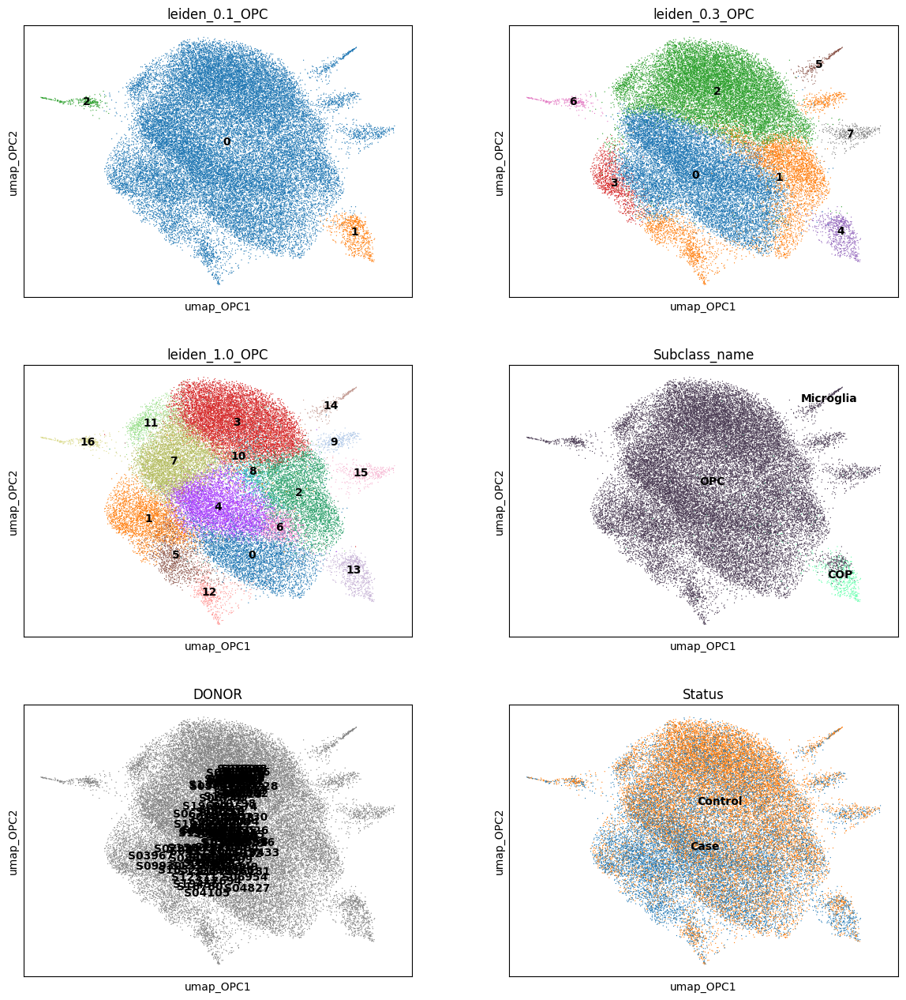

In [19]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, legend_loc="on data")

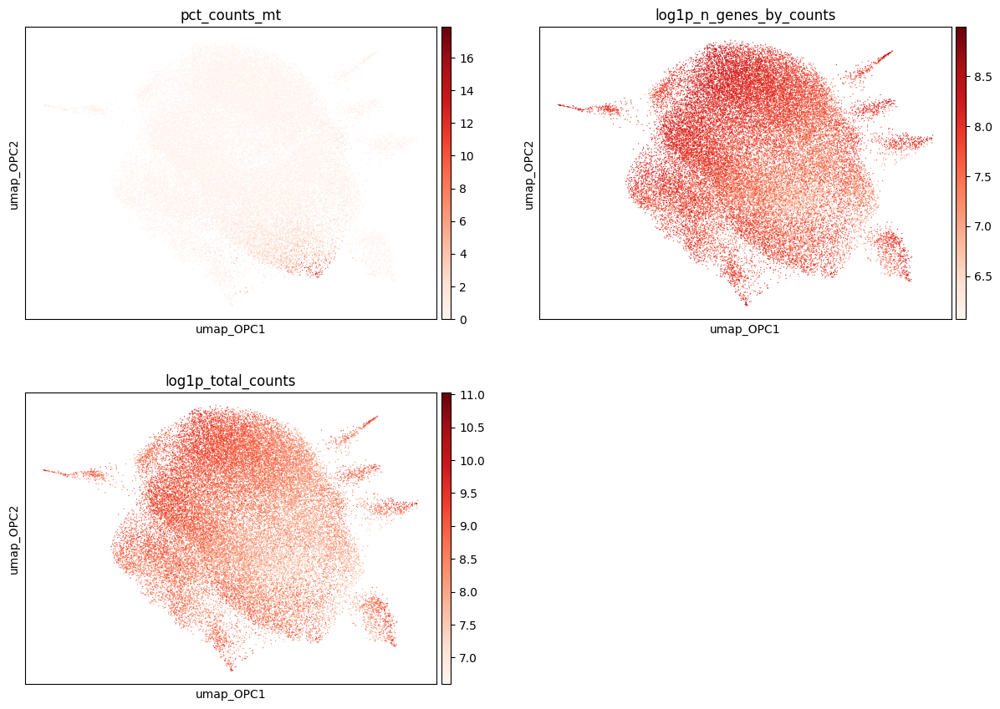

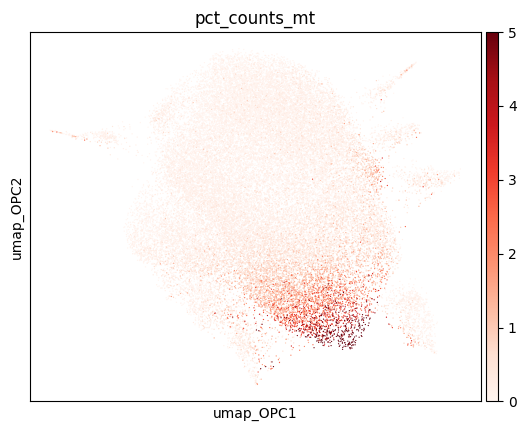

In [26]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data", ncols=2)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt"], vmax=5, cmap="Reds", legend_loc="on data", ncols=2)

In [22]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"


In [23]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(15))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000198712,90.178314,3.980175,0.000000e+00,0.000000e+00,MT-CO2
1,ENSG00000198899,88.537811,4.057436,0.000000e+00,0.000000e+00,MT-ATP6
2,ENSG00000198840,87.925537,3.921218,0.000000e+00,0.000000e+00,MT-ND3
3,ENSG00000198886,87.895599,3.985147,0.000000e+00,0.000000e+00,MT-ND4
4,ENSG00000198938,87.134468,4.160154,0.000000e+00,0.000000e+00,MT-CO3
5,ENSG00000210082,85.922783,3.603429,0.000000e+00,0.000000e+00,MT-RNR2
6,ENSG00000198804,85.541954,4.098957,0.000000e+00,0.000000e+00,MT-CO1
7,ENSG00000198727,83.710434,4.116098,0.000000e+00,0.000000e+00,MT-CYB
8,ENSG00000198763,73.834488,4.649552,0.000000e+00,0.000000e+00,MT-ND2
9,ENSG00000211459,72.598976,3.859937,0.000000e+00,0.000000e+00,MT-RNR1


Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000183117,28.727833,0.258467,1.714047e-181,6.332206e-177,CSMD1
1,ENSG00000179915,28.629202,0.278014,2.910377e-180,5.375902e-176,NRXN1
2,ENSG00000150275,25.634525,0.290423,6.291284e-145,3.320270e-141,PCDH15
3,ENSG00000175161,25.196243,0.254407,4.404080e-140,2.033749e-136,CADM2
4,ENSG00000184226,24.595060,0.243552,1.426647e-133,4.791328e-130,PCDH9
5,ENSG00000184408,24.540295,0.404651,5.490580e-133,1.690321e-129,KCND2
6,ENSG00000176204,24.059195,0.281218,6.688933e-128,1.765066e-124,LRRTM4
7,ENSG00000164796,22.993418,0.314296,5.424651e-117,1.252518e-113,CSMD3
8,ENSG00000183098,22.673180,0.642396,8.242041e-114,1.691587e-110,GPC6
9,ENSG00000067798,22.466265,0.457310,8.874726e-112,1.725574e-108,NAV3


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000170381,47.986900,2.389640,0.000000e+00,0.000000e+00,SEMA3E
1,ENSG00000091129,47.615269,0.897459,0.000000e+00,0.000000e+00,NRCAM
2,ENSG00000152578,44.600605,1.328776,0.000000e+00,0.000000e+00,GRIA4
3,ENSG00000071991,38.086143,2.893875,0.000000e+00,0.000000e+00,CDH19
4,ENSG00000048052,34.620804,1.326043,1.229047e-262,7.567450e-259,HDAC9
5,ENSG00000144278,33.039631,0.768455,2.192001e-239,1.012239e-235,GALNT13
6,ENSG00000136267,32.351574,1.474768,1.318414e-229,4.058848e-226,DGKB
7,ENSG00000038427,31.863010,0.619773,8.693240e-223,2.470418e-219,VCAN
8,ENSG00000181234,30.522146,0.869215,1.324911e-204,3.263078e-201,TMEM132C
9,ENSG00000128585,27.589458,0.685772,1.488912e-167,3.055827e-164,MKLN1


... (24 outputs left out)

Cluster 15:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000147488,23.906063,4.682983,2.648831e-126,9.785576e-122,ST18
1,ENSG00000187147,18.013996,3.689140,1.512985e-72,2.794711e-68,RNF220
2,ENSG00000013297,17.497147,3.812908,1.506304e-68,1.854913e-64,CLDN11
3,ENSG00000179104,16.217209,2.639048,3.811222e-59,3.519950e-55,TMTC2
4,ENSG00000164124,16.169754,4.060026,8.242751e-59,6.090239e-55,TMEM144
5,ENSG00000188580,16.064581,3.310239,4.519087e-58,2.782477e-54,NKAIN2
6,ENSG00000112893,15.500152,2.100514,3.460758e-54,1.826440e-50,MAN2A1
7,ENSG00000135525,14.673135,2.437518,9.581481e-49,4.424608e-45,MAP7
8,ENSG00000114757,14.368268,2.039978,8.185279e-47,3.359875e-43,PEX5L
9,ENSG00000155886,13.792888,1.298869,2.812730e-43,1.039107e-39,SLC24A2


Cluster 16:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000188312,17.571987,3.014060,4.037785e-69,1.491679e-64,CENPP
1,ENSG00000123219,17.093309,6.385159,1.664510e-65,3.074599e-61,CENPK
2,ENSG00000146263,13.971572,3.163287,2.324396e-44,2.862339e-40,MMS22L
3,ENSG00000133119,13.667542,3.141080,1.586637e-42,1.465378e-38,RFC3
4,ENSG00000136492,13.096336,6.009003,3.455364e-39,2.553030e-35,BRIP1
5,ENSG00000119969,12.653734,3.514123,1.066814e-36,6.568550e-33,HELLS
6,ENSG00000044459,12.365982,1.877394,3.993008e-35,2.107339e-31,CNTLN
7,ENSG00000146143,12.016278,2.102868,2.918221e-33,1.347598e-29,PRIM2
8,ENSG00000101868,11.114178,1.836224,1.070323e-28,4.393437e-25,POLA1
9,ENSG00000158169,11.060090,2.043150,1.959004e-28,7.237149e-25,FANCC


In [ ]:
# # chekjc fro  COP marjer
# sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["GPR17", "TCF7L2"], layer="log1p_norm", gene_symbols="gene_symbol", legend_loc="on data")

In [ ]:
# lmu.aucell(adata_nn, ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"], "oligo_score")
# lmu.plot_umap_spatial(adata_nn, color=["oligo_score"], name=NAME, ncols=1, cmap="Reds")

In [ ]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
OPC                         30169
Patch_D1                    19034
Patch_D2                    14060
-Low_quality                13710
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
eMSN_D1D2                    7344
STR SST-CHODL GABA           1991
VIP GABA                     1771
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
non-MSN                       881
COP                           742
ACx MEIS2 GABA                651
STR RSPO2 GABA                530
-fake_phase_D                 513
LAMP5 GABA                    357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


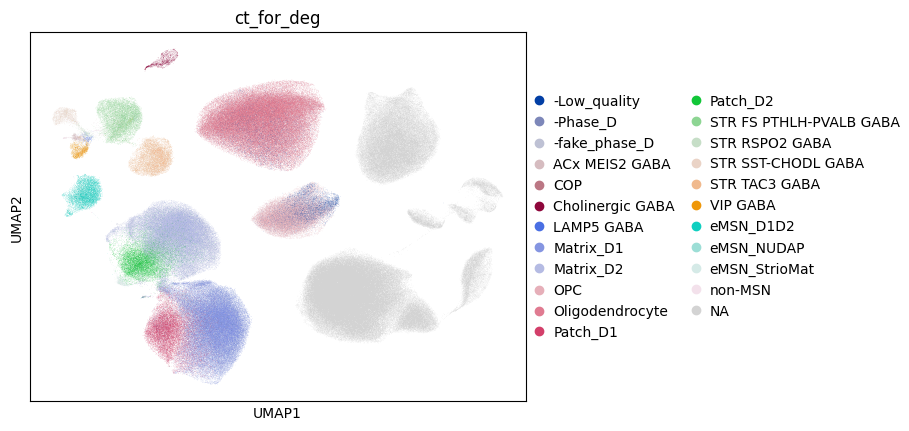

... storing 'tmp_label' as categorical


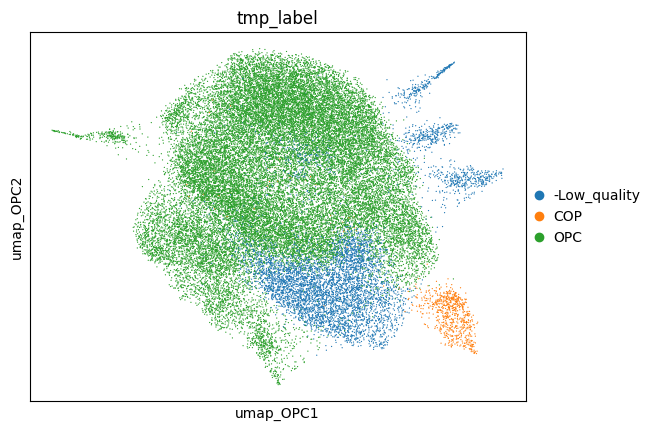

In [30]:
mapping_dict = {
    "14": LOW_QUALITY_LABEL,# microglia doublets
    "9": LOW_QUALITY_LABEL, # astro doublets
    "0": LOW_QUALITY_LABEL, # mito doublets
    "10": LOW_QUALITY_LABEL, # mito doublets
    "15": LOW_QUALITY_LABEL, # oligo doublets
    "6": LOW_QUALITY_LABEL, #



    "13": "COP",

    # OPC all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("OPC")

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

# Glia: Astrocyte

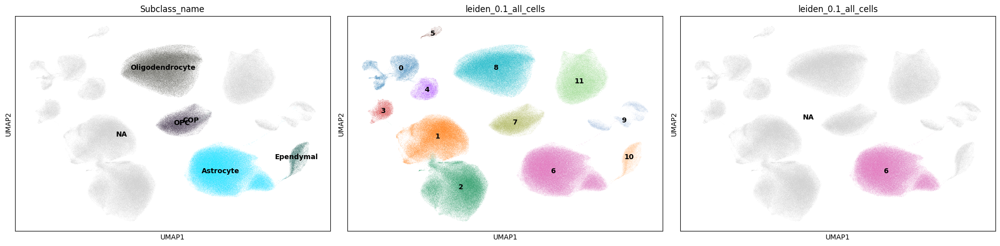

In [33]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["6"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_astro"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-28 18:25:57,351 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 18:25:57 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 18:25:57,353 - harmonypy - INFO -   Parameters:
2026-08-28 18:25:57 | [INFO]   Parameters:
2026-08-28 18:25:57,354 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 18:25:57 | [INFO]     max_iter_harmony: 30
2026-08-28 18:25:57,355 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 18:25:57 | [INFO]     max_iter_kmeans: 20
2026-08-28 18:25:57,356 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 18:25:57 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 18:25:57,357 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 18:25:57 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 18:25:57,359 - harmonypy - INFO -     nclust: 100
2026-08-28 18:25:57 | [INFO]     nclust: 100
2026-08-28 18:25:57,360 - harmonypy - INFO -     block_size: 0.05
2026-08-28 18:25:57 | [INFO]     block_size: 0.05
2026-08-28 18:25:57,363 - harm

Running Harmony batch correction...


2026-08-28 18:26:00,666 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 18:26:00 | [INFO] KMeans initialization complete.
2026-08-28 18:26:00,684 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 18:26:00 | [INFO] Iteration 1 of 30
2026-08-28 18:26:03,371 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 18:26:03 | [INFO] Iteration 2 of 30
2026-08-28 18:26:06,069 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 18:26:06 | [INFO] Iteration 3 of 30
2026-08-28 18:26:08,695 - harmonypy - INFO - Iteration 4 of 30
2026-08-28 18:26:08 | [INFO] Iteration 4 of 30
2026-08-28 18:26:11,386 - harmonypy - INFO - Iteration 5 of 30
2026-08-28 18:26:11 | [INFO] Iteration 5 of 30
2026-08-28 18:26:14,070 - harmonypy - INFO - Iteration 6 of 30
2026-08-28 18:26:14 | [INFO] Iteration 6 of 30
2026-08-28 18:26:16,290 - harmonypy - INFO - Iteration 7 of 30
2026-08-28 18:26:16 | [INFO] Iteration 7 of 30
2026-08-28 18:26:18,699 - harmonypy - INFO - Iteration 8 of 30
2026-08-28 18:26:18 | [INFO] 

Z_corr shape: (149161, 50), n_obs: 149161
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


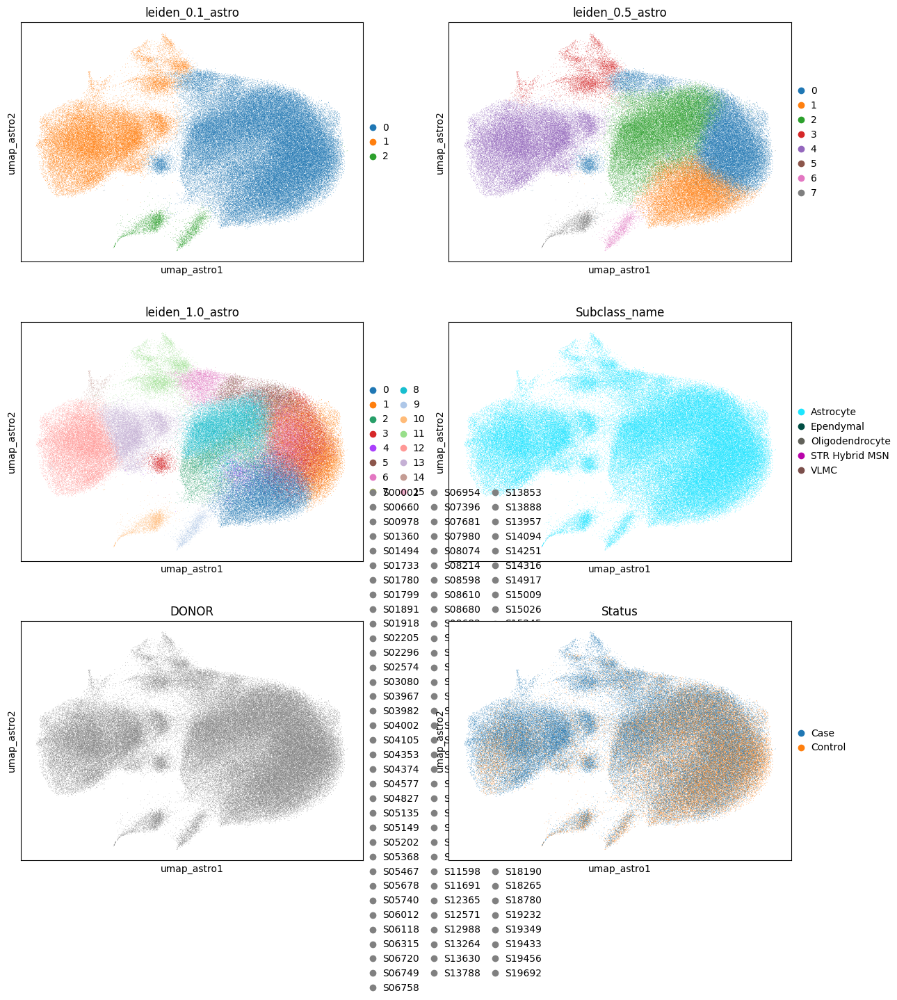

In [34]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

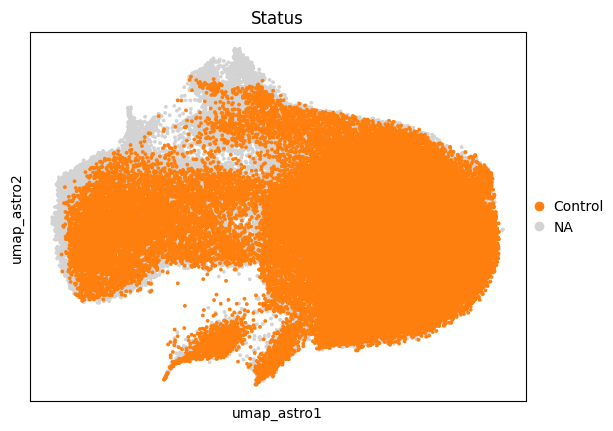

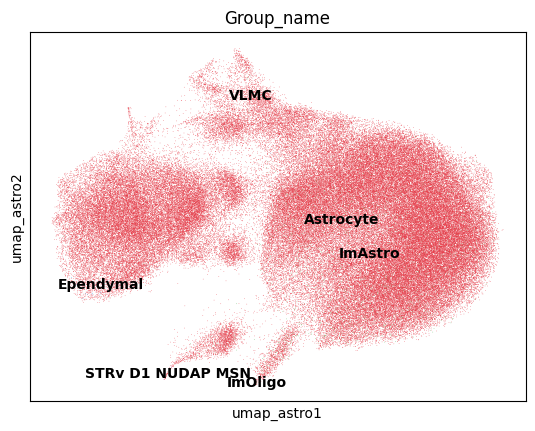

In [47]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ CONDITION_VARIABLE], groups="Control", size=30,ncols=2)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ "Group_name"],ncols=2, legend_loc="on data")

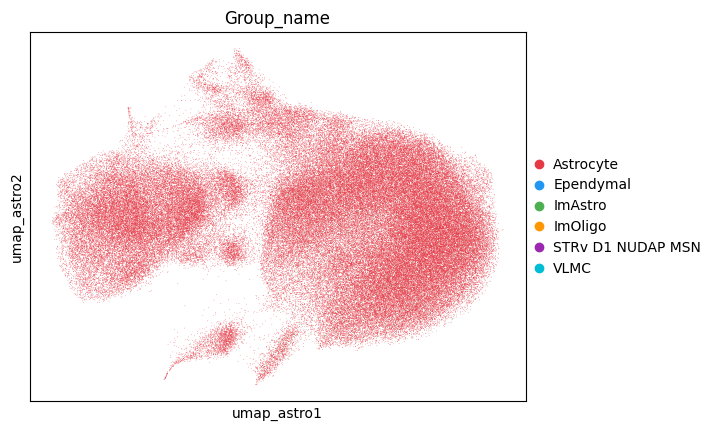

In [38]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], palette=lmu.custom_palette)

In [ ]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.5{NAME}"
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

In [41]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None, 
                                             #groups=["12"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000101439,124.951767,1.921255,0.0,0.0,CST3
1,ENSG00000130203,123.015953,1.806864,0.0,0.0,APOE
2,ENSG00000167996,119.890388,2.010284,0.0,0.0,FTH1
3,ENSG00000087250,113.049034,1.887136,0.0,0.0,MT3
4,ENSG00000164741,107.818474,1.561090,0.0,0.0,DLC1
5,ENSG00000228842,107.717102,1.522246,0.0,0.0,PCDH9-AS2
6,ENSG00000134490,91.861870,1.474558,0.0,0.0,TMEM241
7,ENSG00000255580,90.817001,1.680541,0.0,0.0,AP000462.1
8,ENSG00000125148,89.453087,1.239032,0.0,0.0,MT2A
9,ENSG00000087086,88.648659,1.533133,0.0,0.0,FTL


Cluster 12:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000133083,173.573608,3.337221,0.0,0.0,DCLK1
1,ENSG00000026508,152.607773,2.910712,0.0,0.0,CD44
2,ENSG00000249307,139.494171,3.663681,0.0,0.0,LINC01088
3,ENSG00000156218,131.565964,2.234058,0.0,0.0,ADAMTSL3
4,ENSG00000052126,127.765984,1.858198,0.0,0.0,PLEKHA5
5,ENSG00000185008,124.843925,4.078455,0.0,0.0,ROBO2
6,ENSG00000245532,121.782234,1.200181,0.0,0.0,NEAT1
7,ENSG00000136267,121.284973,2.777143,0.0,0.0,DGKB
8,ENSG00000131095,119.852371,1.545440,0.0,0.0,GFAP
9,ENSG00000251562,117.175629,0.742191,0.0,0.0,MALAT1


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000179915,104.237762,1.178407,0.0,0.0,NRXN1
1,ENSG00000110436,95.663345,1.197745,0.0,0.0,SLC1A2
2,ENSG00000154310,89.743019,0.885036,0.0,0.0,TNIK
3,ENSG00000198822,89.730888,1.646034,0.0,0.0,GRM3
4,ENSG00000046889,86.057999,0.907985,0.0,0.0,PREX2
5,ENSG00000179399,83.816544,0.782307,0.0,0.0,GPC5
6,ENSG00000164741,81.876694,1.336309,0.0,0.0,DLC1
7,ENSG00000164199,81.763527,0.816257,0.0,0.0,ADGRV1
8,ENSG00000163288,81.185684,0.792184,0.0,0.0,GABRB1
9,ENSG00000120251,80.335922,1.237729,0.0,0.0,GRIA2


... (22 outputs left out)

Cluster 15:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000132164,16.887554,4.577256,5.555888e-64,1.026256e-59,SLC6A11
1,ENSG00000083067,16.836800,2.410697,1.311399e-63,1.614901e-59,TRPM3
2,ENSG00000134215,15.829685,5.507270,1.941888e-56,1.665809e-52,VAV3
3,ENSG00000120549,15.820289,4.705272,2.254566e-56,1.665809e-52,KIAA1217
4,ENSG00000182732,15.461304,3.727235,6.330413e-54,3.897741e-50,RGS6
5,ENSG00000168959,15.285780,6.915813,9.511789e-53,5.019915e-49,GRM5
6,ENSG00000041982,15.006775,3.527497,6.629400e-51,3.061374e-47,TNC
7,ENSG00000184672,14.706010,3.550396,5.898405e-49,2.421164e-45,RALYL
8,ENSG00000169302,14.542434,3.864422,6.523171e-48,2.409855e-44,STK32A
9,ENSG00000184408,14.197295,2.770829,9.521727e-46,3.197829e-42,KCND2


Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000173230,27.154800,2.329394,2.222184e-162,8.209415e-158,GOLGB1
1,ENSG00000245532,26.164825,1.499228,6.683538e-151,1.234550e-146,NEAT1
2,ENSG00000251562,25.726208,1.025341,5.952137e-146,5.497245e-142,MALAT1
3,ENSG00000018625,24.704756,1.372088,9.507607e-135,5.980315e-131,ATP1A2
4,ENSG00000135541,24.703894,1.567533,9.712770e-135,5.980315e-131,AHI1
5,ENSG00000166839,24.313755,1.756243,1.402398e-130,6.476098e-127,ANKDD1A
6,ENSG00000232104,24.120855,1.815628,1.510530e-128,6.200391e-125,RFX3-AS1
7,ENSG00000214402,23.554043,2.753136,1.141149e-122,3.513121e-119,LCNL1
8,ENSG00000164048,23.313183,2.859151,3.258638e-120,9.260296e-117,ZNF589
9,ENSG00000168710,22.866035,1.430647,1.012215e-115,2.671018e-112,AHCYL1


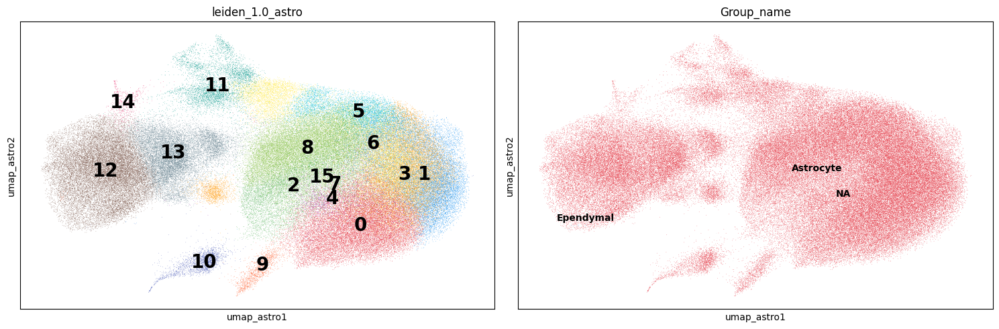

In [39]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"

lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Astrocyte                  121927
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
-Low_quality                40944
OPC                         30169
Patch_D1                    19034
Patch_D2                    14060
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
eMSN_D1D2                    7344
STR SST-CHODL GABA           1991
VIP GABA                     1771
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
non-MSN                       881
COP                           742
ACx MEIS2 GABA                651
STR RSPO2 GABA                530
-fake_phase_D                 513
LAMP5 GABA                    357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


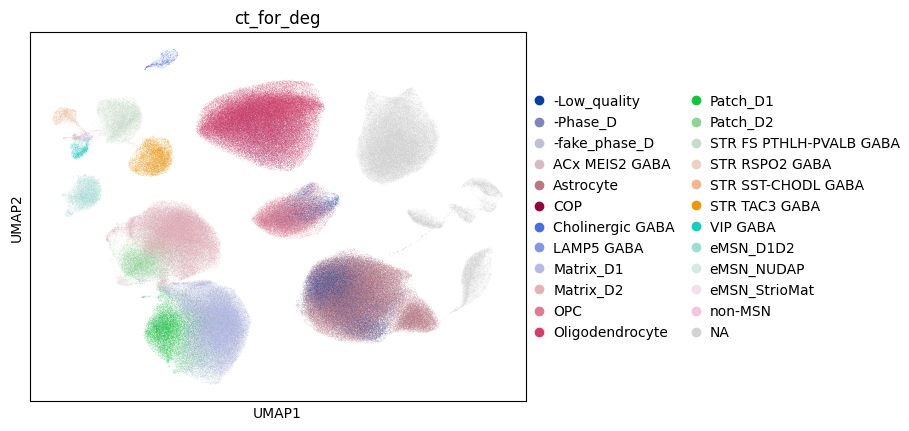

... storing 'tmp_label' as categorical


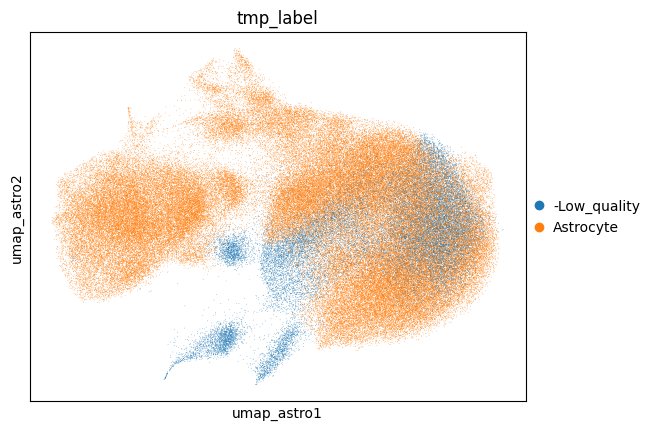

In [43]:
# ATTENTION: in Astr cluster there si always ependymal REAL cells

mapping_dict = {

    "10": LOW_QUALITY_LABEL, # nerons
    "2": LOW_QUALITY_LABEL, #mito
    "9": LOW_QUALITY_LABEL, #oligo
    "3": LOW_QUALITY_LABEL,

    # Astrocyte all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("Astrocyte")

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [ ]:
del adata_nn

# Ependymal

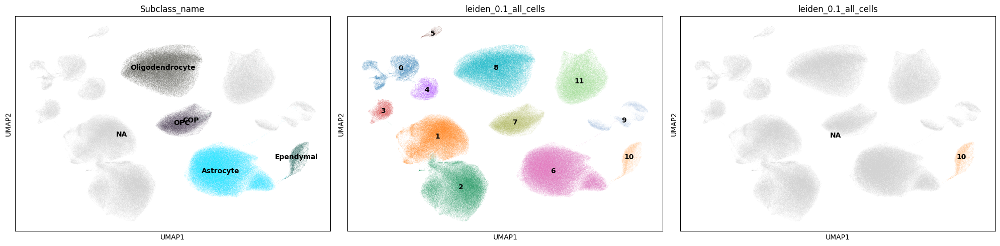

In [49]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["10"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_ependymal"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...
Running Harmony...
Running PCA before Harmony...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-08-28 19:20:52,942 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 19:20:52 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 19:20:52,943 - harmonypy - INFO -   Parameters:
2026-08-28 19:20:52 | [INFO]   Parameters:
2026-08-28 19:20:52,944 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 19:20:52 | [INFO]     max_iter_harmony: 30
2026-08-28 19:20:52,945 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 19:20:52 | [INFO]     max_iter_kmeans: 20
2026-08-28 19:20:52,946 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 19:20:52 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 19:20:52,947 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 19:20:52 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 19:20:52,947 - harmonypy - INFO -     nclust: 100
2026-0

Running Harmony batch correction...


2026-08-28 19:20:53,196 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 19:20:53 | [INFO] KMeans initialization complete.
2026-08-28 19:20:53,200 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 19:20:53 | [INFO] Iteration 1 of 30
2026-08-28 19:20:55,126 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 19:20:55 | [INFO] Iteration 2 of 30
2026-08-28 19:20:57,052 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 19:20:57 | [INFO] Iteration 3 of 30
2026-08-28 19:20:58,850 - harmonypy - INFO - Iteration 4 of 30
2026-08-28 19:20:58 | [INFO] Iteration 4 of 30
2026-08-28 19:21:00,771 - harmonypy - INFO - Iteration 5 of 30
2026-08-28 19:21:00 | [INFO] Iteration 5 of 30
2026-08-28 19:21:02,231 - harmonypy - INFO - Iteration 6 of 30
2026-08-28 19:21:02 | [INFO] Iteration 6 of 30
2026-08-28 19:21:03,751 - harmonypy - INFO - Iteration 7 of 30
2026-08-28 19:21:03 | [INFO] Iteration 7 of 30
2026-08-28 19:21:05,086 - harmonypy - INFO - Iteration 8 of 30
2026-08-28 19:21:05 | [INFO] 

Z_corr shape: (8804, 50), n_obs: 8804
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


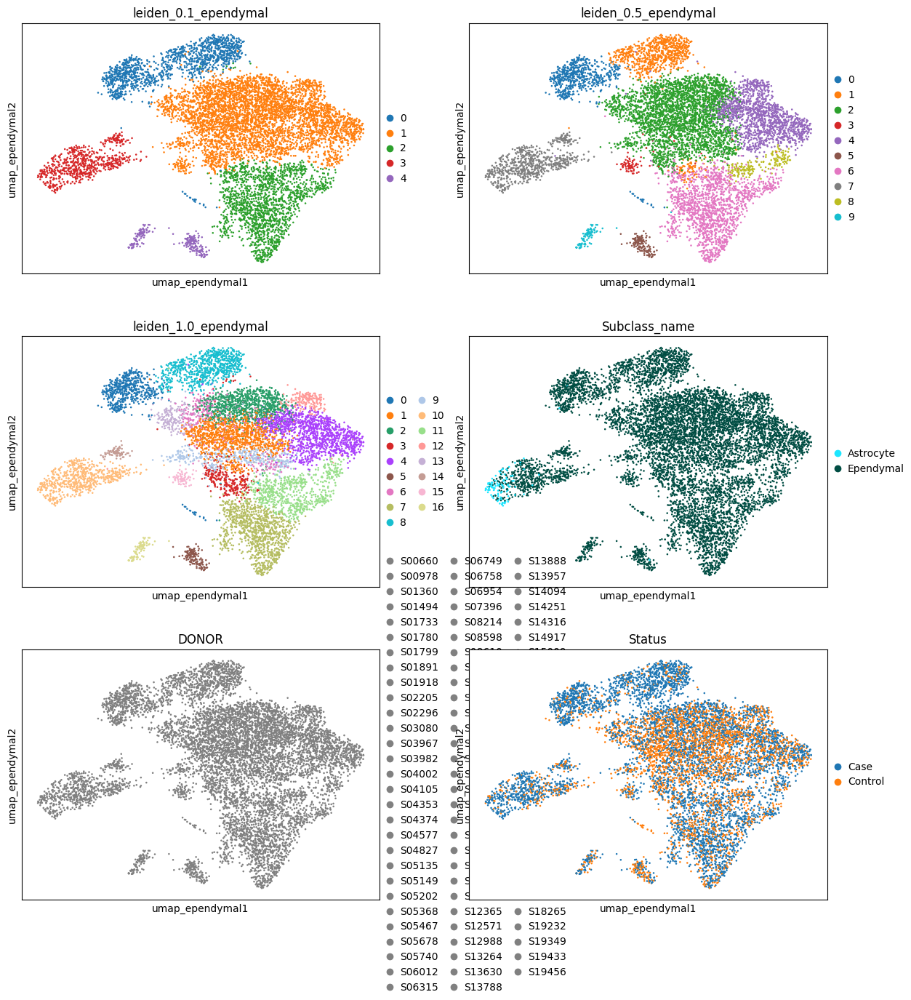

In [50]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

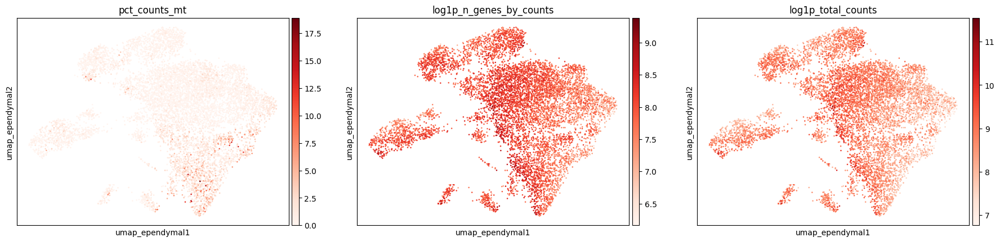

In [52]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")

In [53]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"

In [54]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=10, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(10))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000245532,21.847940,1.146581,8.131952e-106,3.004187e-101,NEAT1
1,ENSG00000145349,15.750391,1.095155,6.825763e-56,5.043283e-52,CAMK2D
2,ENSG00000171877,15.156348,0.985995,6.878944e-52,4.235481e-48,FRMD5
3,ENSG00000110958,15.096410,0.924803,1.709940e-51,9.024330e-48,PTGES3
4,ENSG00000143669,14.860387,1.090235,5.957978e-50,2.751320e-46,LYST
5,ENSG00000100505,14.740050,1.088643,3.565201e-49,1.463436e-45,TRIM9
6,ENSG00000026508,14.699191,1.759230,6.523385e-49,2.409934e-45,CD44
7,ENSG00000112851,14.422515,0.650072,3.734829e-47,1.254325e-43,ERBIN
8,ENSG00000078114,14.408261,0.458562,4.591211e-47,1.413443e-43,NEBL
9,ENSG00000144381,14.159747,1.007262,1.625789e-45,4.290110e-42,HSPD1


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000007174,26.631014,0.577749,2.969931e-156,1.567402e-152,DNAH9
1,ENSG00000273540,22.736593,1.256071,1.947726e-114,3.997491e-111,AGBL1
2,ENSG00000174776,22.597273,0.522329,4.609856e-113,8.515096e-110,WDR49
3,ENSG00000186094,22.461269,0.359545,9.931017e-112,1.747055e-108,AGBL4
4,ENSG00000232505,21.589581,0.818475,2.250440e-103,3.614696e-100,AL672167.2
5,ENSG00000188596,21.522654,0.359744,9.553345e-103,1.470538e-99,CFAP54
6,ENSG00000156042,20.987719,0.571616,8.492556e-98,1.254962e-94,CFAP70
7,ENSG00000197826,20.982838,0.351350,9.410518e-98,1.337126e-94,C4orf22
8,ENSG00000157423,20.886889,0.398411,7.046223e-97,9.641060e-94,HYDIN
9,ENSG00000130413,20.850615,0.471107,1.504802e-96,1.985424e-93,STK33


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000198712,47.609707,2.997331,0.000000e+00,0.000000e+00,MT-CO2
1,ENSG00000198840,46.646137,2.955940,0.000000e+00,0.000000e+00,MT-ND3
2,ENSG00000198886,46.359325,2.834739,0.000000e+00,0.000000e+00,MT-ND4
3,ENSG00000198938,45.959469,3.113949,0.000000e+00,0.000000e+00,MT-CO3
4,ENSG00000198727,44.925831,2.857156,0.000000e+00,0.000000e+00,MT-CYB
5,ENSG00000198899,43.485054,2.705691,0.000000e+00,0.000000e+00,MT-ATP6
6,ENSG00000198804,43.090370,2.706266,0.000000e+00,0.000000e+00,MT-CO1
7,ENSG00000198763,38.609695,2.793834,0.000000e+00,0.000000e+00,MT-ND2
8,ENSG00000198786,36.353352,2.189868,2.326188e-289,9.548486e-286,MT-ND5
9,ENSG00000166165,35.743061,2.193916,8.479870e-280,3.132718e-276,CKB


Cluster 3:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185565,25.489096,1.813746,2.604141e-143,9.620477e-139,LSAMP
1,ENSG00000175161,22.831408,3.195144,2.236368e-115,4.130907e-111,CADM2
2,ENSG00000148655,21.064398,2.326201,1.687589e-98,2.078154e-94,LRMDA
3,ENSG00000169862,19.278767,1.162881,8.098401e-83,7.479481e-79,CTNND2
4,ENSG00000163288,16.895487,1.587217,4.856891e-64,1.631165e-60,GABRB1
5,ENSG00000156475,16.829575,1.053123,1.481610e-63,4.561259e-60,PPP2R2B
6,ENSG00000168843,16.802996,2.333004,2.320220e-63,6.593529e-60,FSTL5
7,ENSG00000271860,16.780571,1.373739,3.385697e-63,8.934129e-60,AL589740.1
8,ENSG00000179399,16.477400,2.367736,5.333026e-61,1.313453e-57,GPC5
9,ENSG00000150471,15.777215,1.984314,4.464539e-56,9.701969e-53,ADGRL3


Cluster 4:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000169306,12.867613,4.445622,6.848588e-38,2.530074e-33,IL1RAPL1
1,ENSG00000175161,9.958704,1.999827,2.310549e-23,4.267930e-19,CADM2
2,ENSG00000021645,9.794161,2.782194,1.192843e-22,1.468907e-18,NRXN3
3,ENSG00000185774,9.235392,3.692666,2.573434e-20,2.376759e-16,KCNIP4
4,ENSG00000155886,8.722921,4.749190,2.711143e-18,2.003155e-14,SLC24A2
5,ENSG00000151150,8.647234,4.269762,5.276284e-18,3.248696e-14,ANK3
6,ENSG00000183230,7.990630,2.332900,1.342509e-15,7.085186e-12,CTNNA3
7,ENSG00000150672,7.953042,1.062193,1.819872e-15,8.403943e-12,DLG2
8,ENSG00000155849,7.534217,3.709218,4.912733e-14,2.016568e-10,ELMO1
9,ENSG00000174469,7.385230,3.417248,1.521902e-13,5.622361e-10,CNTNAP2


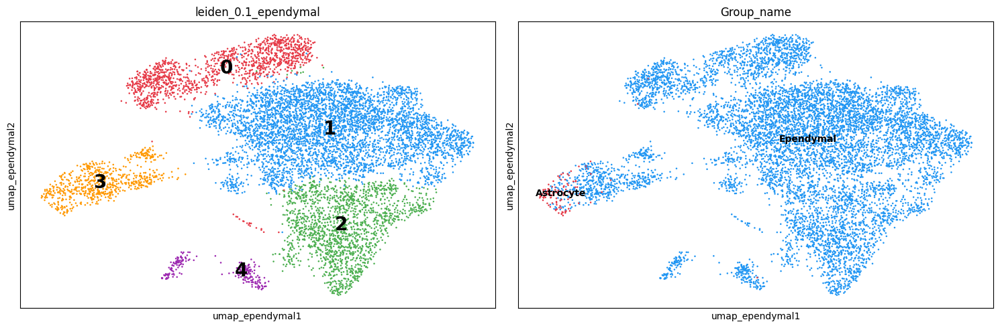

In [55]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Astrocyte                  121927
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
-Low_quality                44992
OPC                         30169
Patch_D1                    19034
Patch_D2                    14060
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
eMSN_D1D2                    7344
Ependymal                    4756
STR SST-CHODL GABA           1991
VIP GABA                     1771
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
non-MSN                       881
COP                           742
ACx MEIS2 GABA                651
STR RSPO2 GABA                530
-fake_phase_D                 513
LAMP5 GABA                    357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


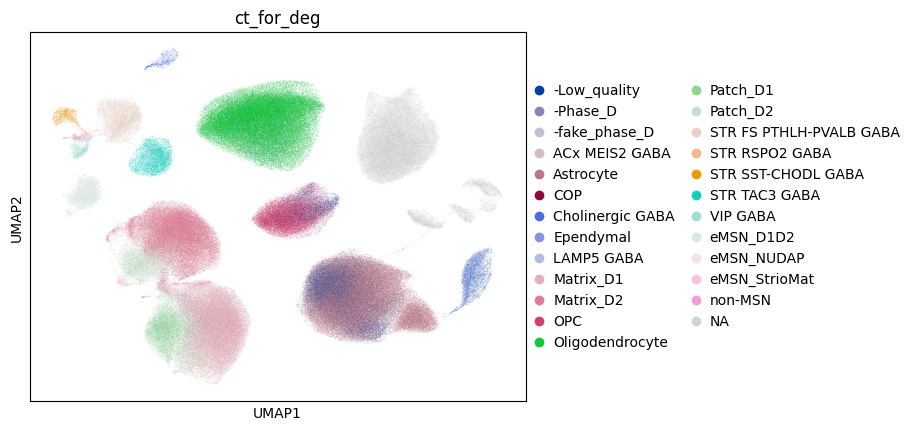

... storing 'tmp_label' as categorical


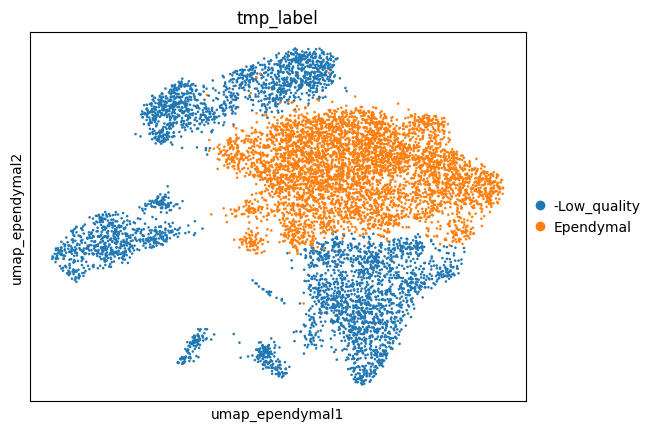

In [56]:
# ATTENTION: in Astr cluster there si always ependymal REAL cells

mapping_dict = {

    "1": "Ependymal",
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(LOW_QUALITY_LABEL)

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

# Vascular

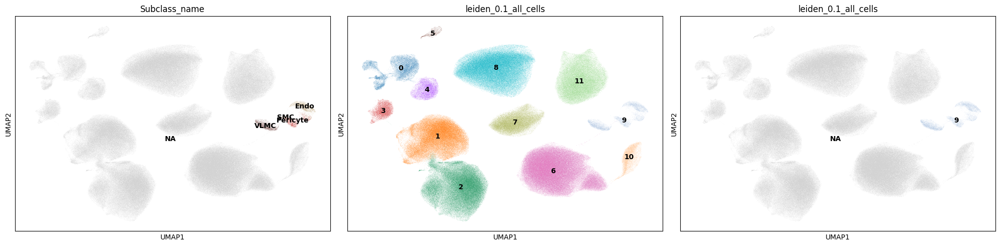

In [58]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["9"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["vascular"]
NAME="_vascular"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-28 20:07:11,721 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 20:07:11 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 20:07:11,722 - harmonypy - INFO -   Parameters:
2026-08-28 20:07:11 | [INFO]   Parameters:
2026-08-28 20:07:11,723 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 20:07:11 | [INFO]     max_iter_harmony: 30
2026-08-28 20:07:11,724 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 20:07:11 | [INFO]     max_iter_kmeans: 20
2026-08-28 20:07:11,725 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 20:07:11 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 20:07:11,726 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 20:07:11 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 20:07:11,727 - harmonypy - INFO -     nclust: 100
2026-08-28 20:07:11 | [INFO]     nclust: 100
2026-08-28 20:07:11,728 - harmonypy - INFO -     block_size: 0.05
2026-08-28 20:07:11 | [INFO]     block_size: 0.05
2026-08-28 20:07:11,730 - harm

Running Harmony batch correction...


2026-08-28 20:07:11,970 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 20:07:11 | [INFO] KMeans initialization complete.
2026-08-28 20:07:11,974 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 20:07:11 | [INFO] Iteration 1 of 30
2026-08-28 20:07:14,225 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 20:07:14 | [INFO] Iteration 2 of 30
2026-08-28 20:07:16,796 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 20:07:16 | [INFO] Iteration 3 of 30
2026-08-28 20:07:18,561 - harmonypy - INFO - Iteration 4 of 30
2026-08-28 20:07:18 | [INFO] Iteration 4 of 30
2026-08-28 20:07:21,027 - harmonypy - INFO - Iteration 5 of 30
2026-08-28 20:07:21 | [INFO] Iteration 5 of 30
2026-08-28 20:07:22,580 - harmonypy - INFO - Iteration 6 of 30
2026-08-28 20:07:22 | [INFO] Iteration 6 of 30
2026-08-28 20:07:24,107 - harmonypy - INFO - Iteration 7 of 30
2026-08-28 20:07:24 | [INFO] Iteration 7 of 30
2026-08-28 20:07:26,103 - harmonypy - INFO - Iteration 8 of 30
2026-08-28 20:07:26 | [INFO] 

Z_corr shape: (8822, 50), n_obs: 8822
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


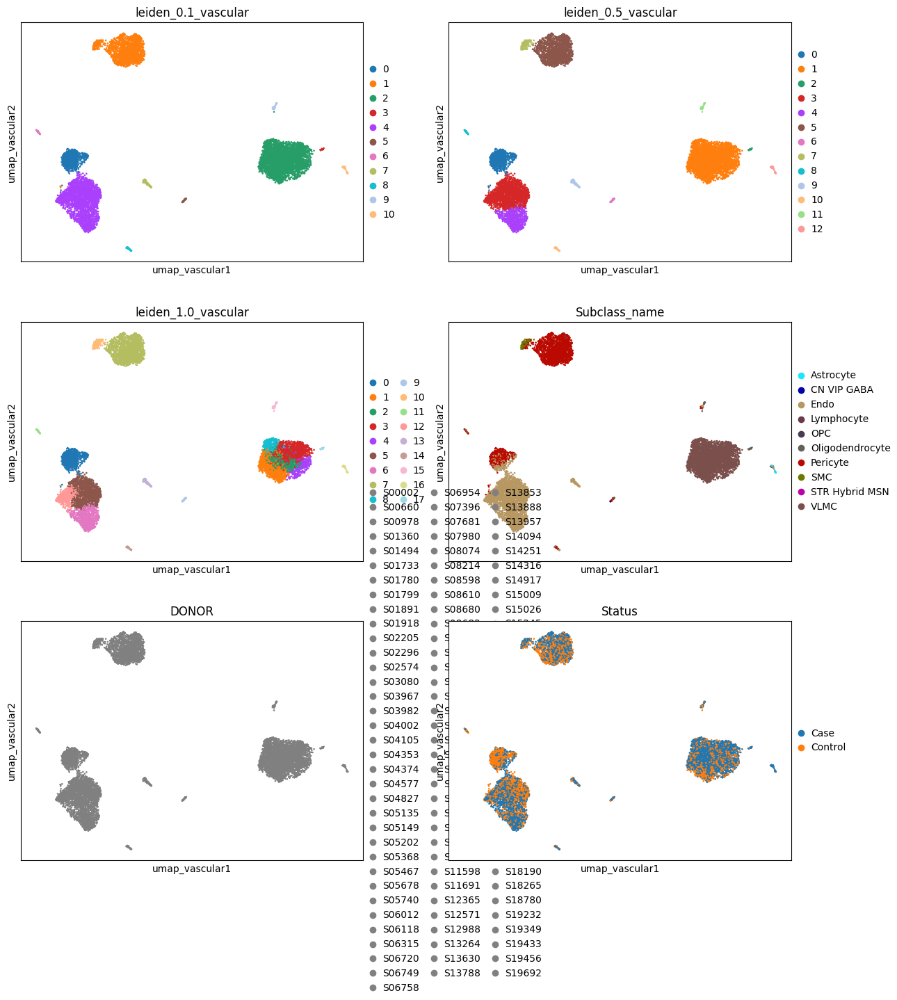

In [59]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

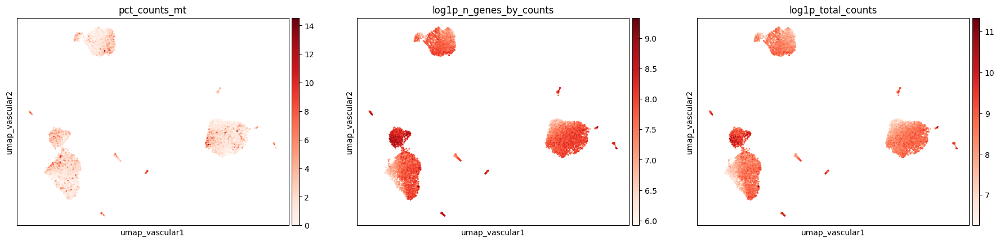

In [61]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ "pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")

In [66]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.5{NAME}"

In [67]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000143248,36.679127,3.839060,1.571540e-294,5.805740e-290,RGS5
1,ENSG00000185633,29.805731,3.074557,3.292566e-195,6.081863e-191,NDUFA4L2
2,ENSG00000034510,28.610630,2.679173,4.955243e-180,6.102052e-176,TMSB10
3,ENSG00000205542,28.567949,2.571376,1.681284e-179,1.552791e-175,TMSB4X
4,ENSG00000165949,28.322769,2.916698,1.812431e-176,1.339133e-172,IFI27
5,ENSG00000169507,28.200560,2.838594,5.756010e-175,3.544071e-171,SLC38A11
6,ENSG00000179603,27.692671,2.981465,8.556039e-169,4.515511e-165,GRM8
7,ENSG00000113231,27.516424,2.742679,1.116740e-166,5.156965e-163,PDE8B
8,ENSG00000198822,27.480459,2.797547,3.006331e-166,1.234032e-162,GRM3
9,ENSG00000233927,27.016405,2.221601,9.483222e-161,3.503387e-157,RPS28


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185070,75.146774,7.241561,0.0,0.0,FLRT2
1,ENSG00000215386,71.569328,4.199783,0.0,0.0,MIR99AHG
2,ENSG00000154258,70.552155,4.767243,0.0,0.0,ABCA9
3,ENSG00000140538,70.389687,4.403404,0.0,0.0,NTRK3
4,ENSG00000013297,69.212524,6.624413,0.0,0.0,CLDN11
5,ENSG00000122870,69.127022,6.333731,0.0,0.0,BICC1
6,ENSG00000196569,68.269882,3.736232,0.0,0.0,LAMA2
7,ENSG00000187147,67.966766,4.556333,0.0,0.0,RNF220
8,ENSG00000103888,67.104881,6.129889,0.0,0.0,CEMIP
9,ENSG00000249307,64.550179,6.854399,0.0,0.0,LINC01088


Cluster 3:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000102755,54.207352,4.830012,0.0,0.0,FLT1
1,ENSG00000206190,52.616302,4.274274,0.0,0.0,ATP10A
2,ENSG00000085563,49.439640,4.110493,0.0,0.0,ABCB1
3,ENSG00000164181,48.376347,4.030939,0.0,0.0,ELOVL7
4,ENSG00000184005,47.343060,3.522408,0.0,0.0,ST6GALNAC3
5,ENSG00000085276,44.607616,3.630376,0.0,0.0,MECOM
6,ENSG00000088387,44.375114,2.749489,0.0,0.0,DOCK9
7,ENSG00000127329,44.373672,3.589691,0.0,0.0,PTPRB
8,ENSG00000184113,43.769470,3.461076,0.0,0.0,CLDN5
9,ENSG00000118777,43.258667,3.547831,0.0,0.0,ABCG2


... (16 outputs left out)

Cluster 12:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000175497,10.699461,7.571427,1.023723e-26,3.781942e-22,DPP10
1,ENSG00000184226,10.494885,6.127202,9.118816e-26,1.684382e-21,PCDH9
2,ENSG00000185565,9.884063,4.889857,4.881296e-23,6.010991e-19,LSAMP
3,ENSG00000156475,9.825903,6.090399,8.709032e-23,8.043444e-19,PPP2R2B
4,ENSG00000169862,9.418117,6.643548,4.592522e-21,3.393231e-17,CTNND2
5,ENSG00000178568,9.278463,5.757004,1.719405e-20,1.058666e-16,ERBB4
6,ENSG00000151322,9.161389,4.263918,5.123353e-20,2.703886e-16,NPAS3
7,ENSG00000185737,9.136053,4.302258,6.477332e-20,2.991151e-16,NRG3
8,ENSG00000234377,9.096497,8.029817,9.329299e-20,3.829470e-16,RNF219-AS1
9,ENSG00000182667,9.070609,4.680309,1.183540e-19,4.372352e-16,NTM


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000183098,7.215247,6.698162,5.383627e-13,1.988873e-08,GPC6
1,ENSG00000136842,7.029387,5.364789,2.074423e-12,3.831771e-08,TMOD1
2,ENSG00000061455,6.919032,8.327272,4.547402e-12,5.599823e-08,PRDM6
3,ENSG00000173068,6.870776,5.312108,6.385350e-12,5.897349e-08,BNC2
4,ENSG00000172296,6.726932,6.234034,1.732778e-11,1.280281e-07,SPTLC3
5,ENSG00000183580,6.679247,3.332063,2.401724e-11,1.356742e-07,FBXL7
6,ENSG00000158467,6.669271,3.974062,2.570770e-11,1.356742e-07,AHCYL2
7,ENSG00000156218,6.532458,5.112936,6.469872e-11,2.921282e-07,ADAMTSL3
8,ENSG00000165995,6.518175,3.651238,7.116786e-11,2.921282e-07,CACNB2
9,ENSG00000156113,6.480072,8.303648,9.167912e-11,3.386902e-07,KCNMA1


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

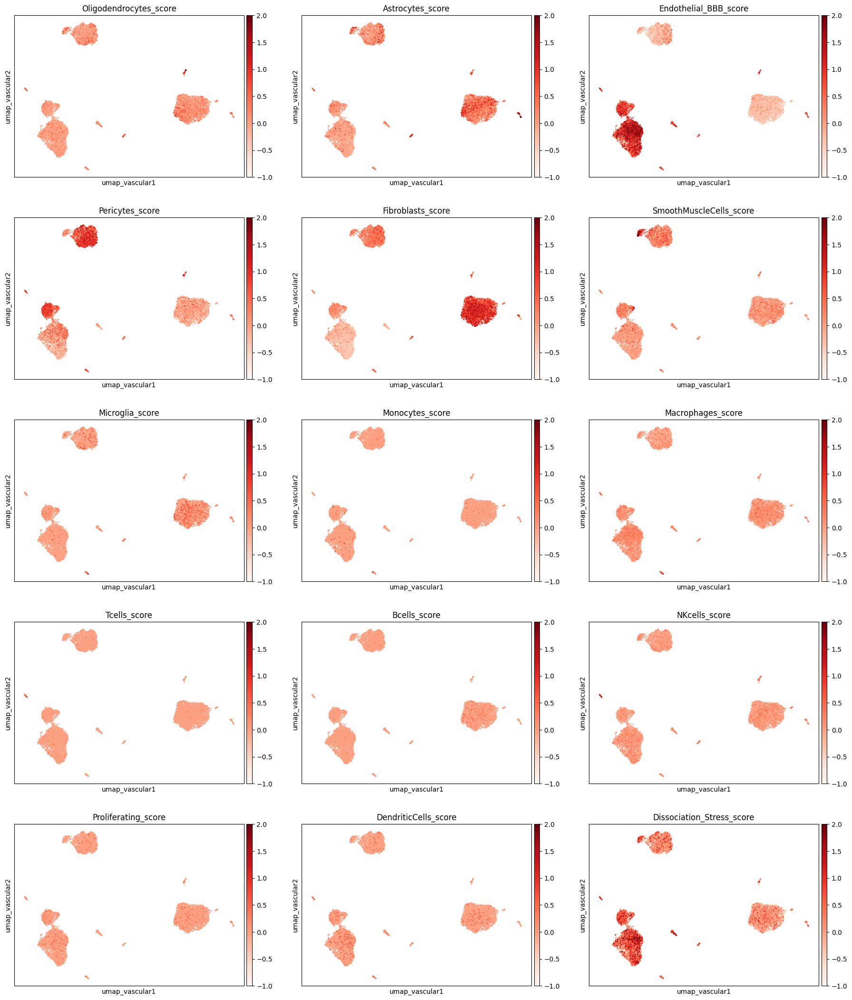

In [68]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


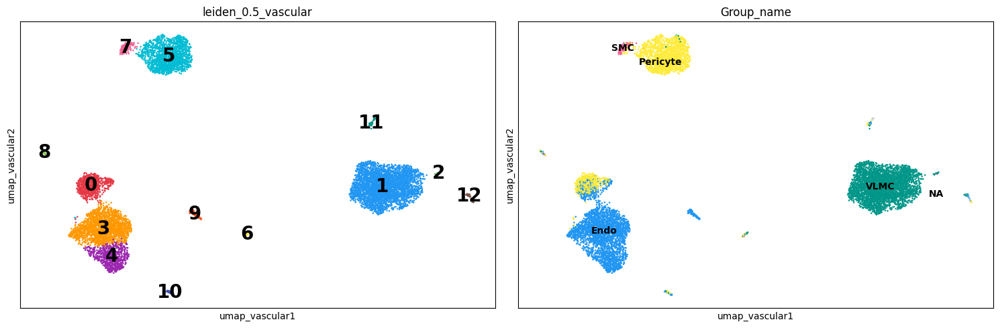

In [69]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Astrocyte                  121927
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
-Low_quality                45251
OPC                         30169
Patch_D1                    19034
Patch_D2                    14060
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
eMSN_D1D2                    7344
Ependymal                    4756
Fibroblasts                  3442
Endothelial_BBB              2729
STR SST-CHODL GABA           1991
VIP GABA                     1771
Pericytes                    1525
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
non-MSN                       881
COP                           742
Activated_Pericytes           739
ACx MEIS2 GABA                651
STR RSPO2 GABA                530
-fake_phase_D                 513
LAMP5 GABA                    357
SmoothMuscleCells             128
Nam

... storing 'ct_for_deg' as categorical


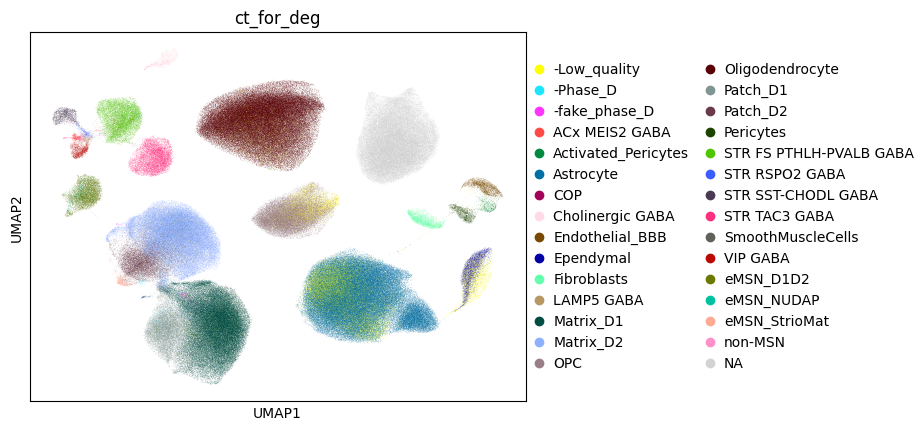

... storing 'tmp_label' as categorical


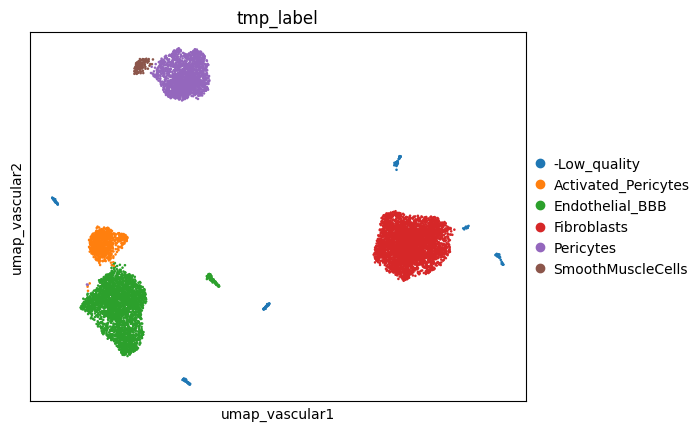

In [71]:
"""
VASCUALAR
    - Endothelial_BBB
    - Pericytes
    - Fibroblasts / VLMC
    - SmoothMuscleCells
"""

mapping_dict = {
    "1": "Fibroblasts",
    "7": "SmoothMuscleCells",

    "3": "Endothelial_BBB",
    "4": "Endothelial_BBB",
    "9": "Endothelial_BBB", # artery: EFNB2


    "5": "Pericytes",
    "0": "Activated_Pericytes", #RGS5

    # "8": "Tcell" #????


    # LOW_QUALITY_LABEL all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(LOW_QUALITY_LABEL)

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Immune: Microglia + Lymphocytes

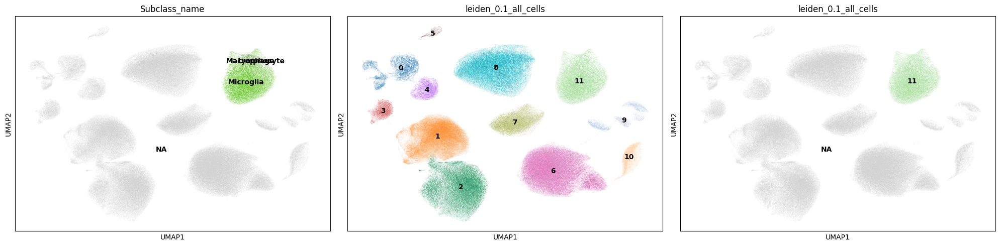

In [80]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["11"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["immune"]
NAME="_microglia"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-28 20:58:59,005 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-28 20:58:59 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-28 20:58:59,007 - harmonypy - INFO -   Parameters:
2026-08-28 20:58:59 | [INFO]   Parameters:
2026-08-28 20:58:59,007 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-28 20:58:59 | [INFO]     max_iter_harmony: 30
2026-08-28 20:58:59,008 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-28 20:58:59 | [INFO]     max_iter_kmeans: 20
2026-08-28 20:58:59,009 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-28 20:58:59 | [INFO]     epsilon_cluster: 1e-05
2026-08-28 20:58:59,010 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-28 20:58:59 | [INFO]     epsilon_harmony: 0.0001
2026-08-28 20:58:59,011 - harmonypy - INFO -     nclust: 100
2026-08-28 20:58:59 | [INFO]     nclust: 100
2026-08-28 20:58:59,011 - harmonypy - INFO -     block_size: 0.05
2026-08-28 20:58:59 | [INFO]     block_size: 0.05
2026-08-28 20:58:59,013 - harm

Running Harmony batch correction...


2026-08-28 20:59:00,281 - harmonypy - INFO - KMeans initialization complete.
2026-08-28 20:59:00 | [INFO] KMeans initialization complete.
2026-08-28 20:59:00,289 - harmonypy - INFO - Iteration 1 of 30
2026-08-28 20:59:00 | [INFO] Iteration 1 of 30
2026-08-28 20:59:02,669 - harmonypy - INFO - Iteration 2 of 30
2026-08-28 20:59:02 | [INFO] Iteration 2 of 30
2026-08-28 20:59:05,047 - harmonypy - INFO - Iteration 3 of 30
2026-08-28 20:59:05 | [INFO] Iteration 3 of 30
2026-08-28 20:59:07,423 - harmonypy - INFO - Iteration 4 of 30
2026-08-28 20:59:07 | [INFO] Iteration 4 of 30
2026-08-28 20:59:09,753 - harmonypy - INFO - Iteration 5 of 30
2026-08-28 20:59:09 | [INFO] Iteration 5 of 30
2026-08-28 20:59:11,838 - harmonypy - INFO - Iteration 6 of 30
2026-08-28 20:59:11 | [INFO] Iteration 6 of 30
2026-08-28 20:59:13,419 - harmonypy - INFO - Iteration 7 of 30
2026-08-28 20:59:13 | [INFO] Iteration 7 of 30
2026-08-28 20:59:15,330 - harmonypy - INFO - Iteration 8 of 30
2026-08-28 20:59:15 | [INFO] 

Z_corr shape: (59479, 50), n_obs: 59479
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


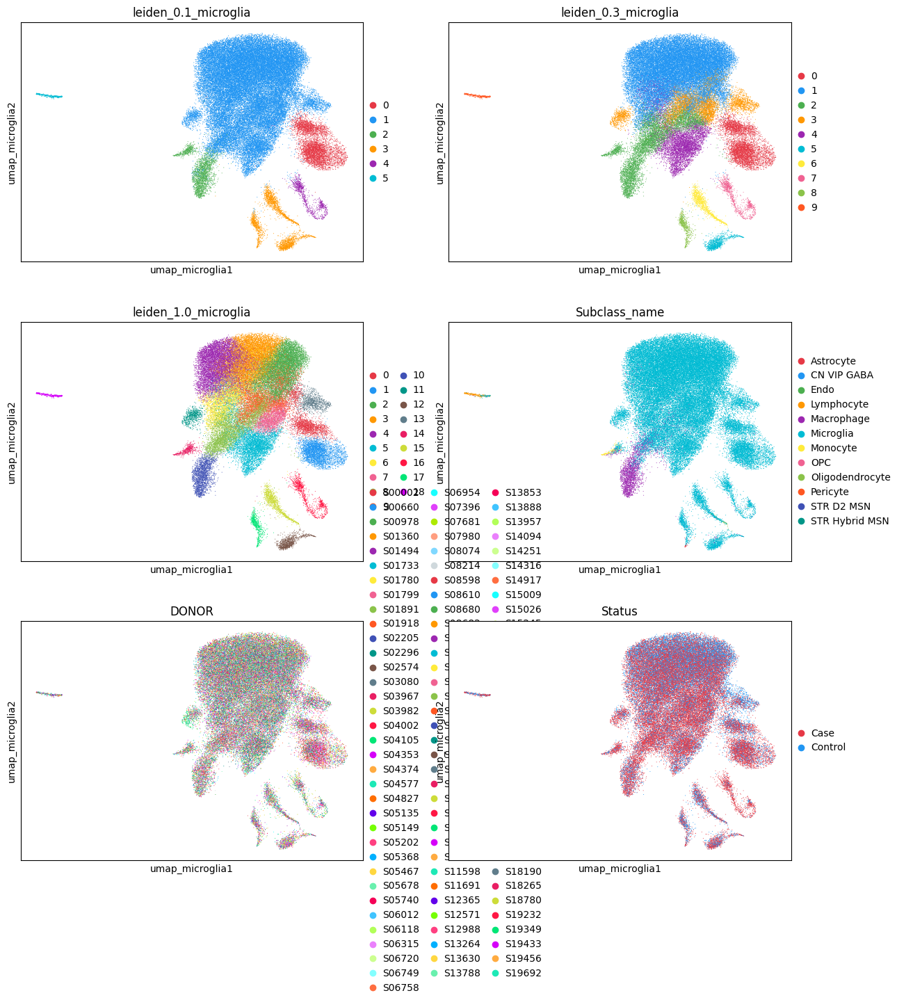

In [81]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)

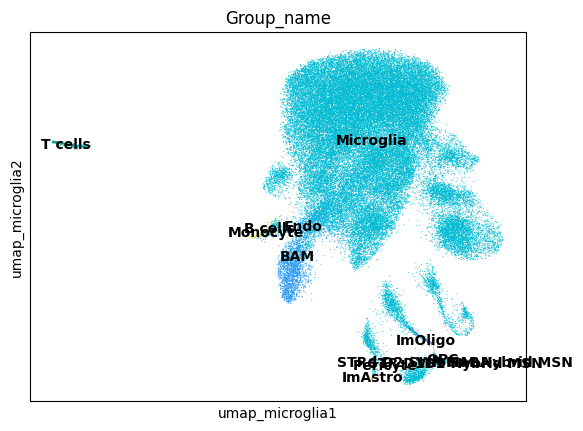

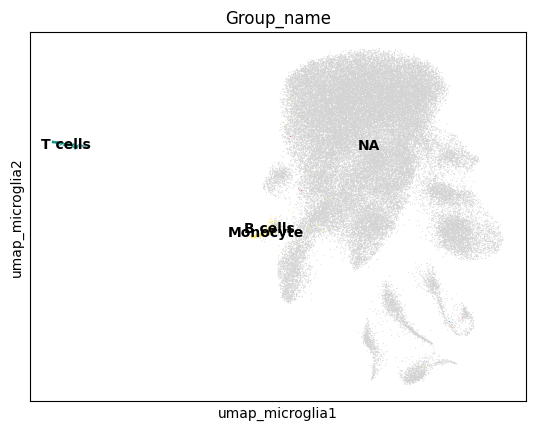

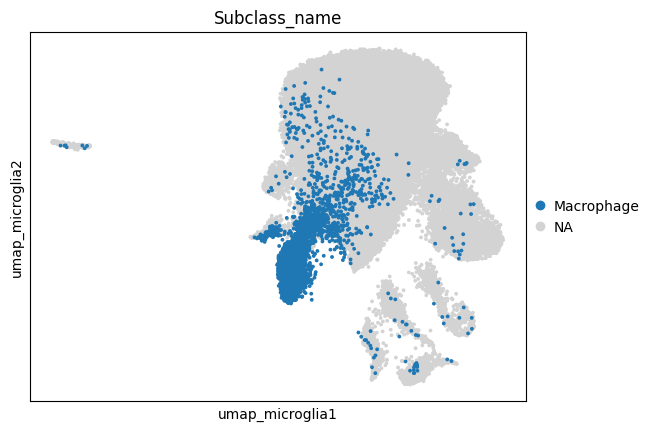

In [82]:


sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], ncols=2, palette=preprocessing.custom_palette, legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=["T cells", "Monocyte", "B cells", "Macrophage"], ncols=2, palette=preprocessing.custom_palette, legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], groups=["Macrophage"], ncols=2, palette=["#1f77b4"], size=30)

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

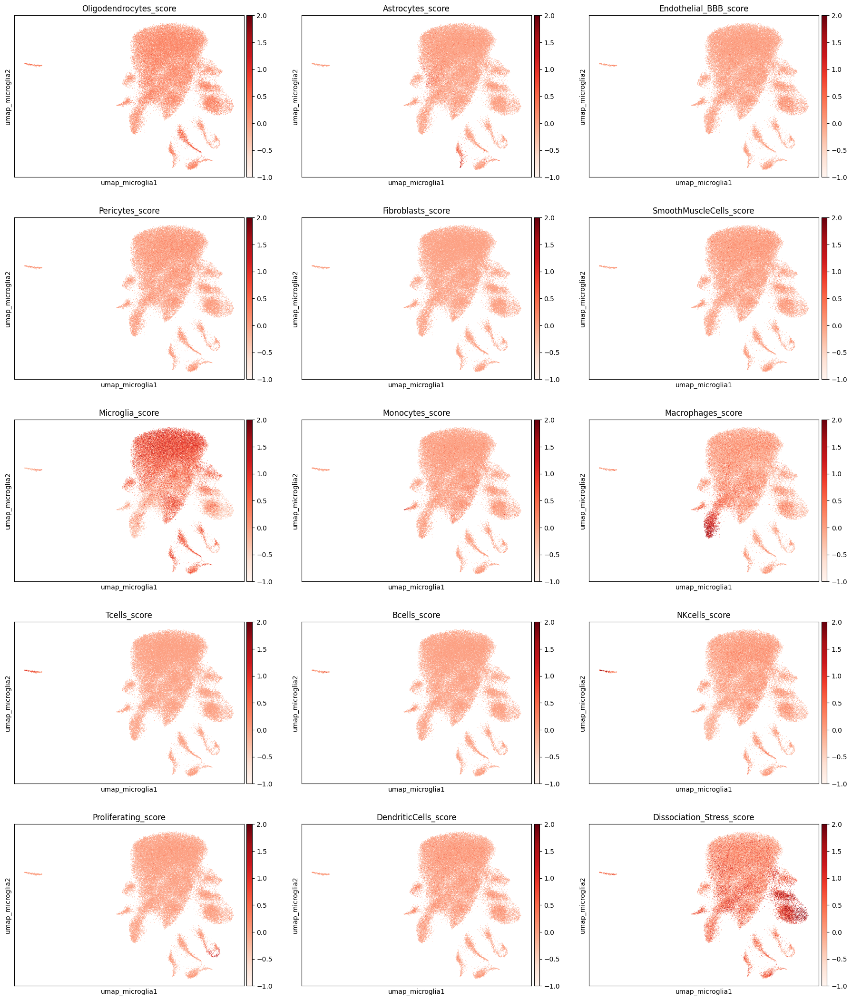

In [83]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


In [88]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"

In [90]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000080824,55.233284,3.692421,0.000000e+00,0.000000e+00,HSP90AA1
1,ENSG00000204389,53.304859,3.203814,0.000000e+00,0.000000e+00,HSPA1A
2,ENSG00000120694,49.748268,3.804139,0.000000e+00,0.000000e+00,HSPH1
3,ENSG00000132002,44.641731,4.324349,0.000000e+00,0.000000e+00,DNAJB1
4,ENSG00000106211,42.999435,3.596115,0.000000e+00,0.000000e+00,HSPB1
5,ENSG00000204388,41.226967,2.936686,0.000000e+00,0.000000e+00,HSPA1B
6,ENSG00000122884,41.077671,2.521147,0.000000e+00,0.000000e+00,P4HA1
7,ENSG00000150991,40.083256,2.799344,0.000000e+00,0.000000e+00,UBC
8,ENSG00000144381,36.427753,2.916125,1.548355e-290,6.355653e-287,HSPD1
9,ENSG00000251562,34.756844,0.646956,1.092342e-264,4.035440e-261,MALAT1


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000067798,48.650879,1.145205,0.000000e+00,0.000000e+00,NAV3
1,ENSG00000169313,47.873070,1.339378,0.000000e+00,0.000000e+00,P2RY12
2,ENSG00000144893,44.900101,1.406472,0.000000e+00,0.000000e+00,MED12L
3,ENSG00000101463,43.018620,1.212411,0.000000e+00,0.000000e+00,SYNDIG1
4,ENSG00000250125,42.565434,1.202844,0.000000e+00,0.000000e+00,LINC02232
5,ENSG00000184005,40.747578,1.035407,0.000000e+00,0.000000e+00,ST6GALNAC3
6,ENSG00000146090,40.586159,1.255744,0.000000e+00,0.000000e+00,RASGEF1C
7,ENSG00000171914,39.551987,1.069747,0.000000e+00,0.000000e+00,TLN2
8,ENSG00000273409,39.527473,1.452821,0.000000e+00,0.000000e+00,AP003481.1
9,ENSG00000249867,39.269176,1.649928,0.000000e+00,0.000000e+00,AC090833.1


Cluster 8:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000188641,50.852222,1.885593,0.000000e+00,0.000000e+00,DPYD
1,ENSG00000114861,48.373379,1.395744,0.000000e+00,0.000000e+00,FOXP1
2,ENSG00000188906,47.542912,1.738530,0.000000e+00,0.000000e+00,LRRK2
3,ENSG00000197555,43.713612,1.527156,0.000000e+00,0.000000e+00,SIPA1L1
4,ENSG00000177575,41.461628,2.031970,0.000000e+00,0.000000e+00,CD163
5,ENSG00000090104,40.572445,1.638221,0.000000e+00,0.000000e+00,RGS1
6,ENSG00000038945,39.226387,1.347608,0.000000e+00,0.000000e+00,MSR1
7,ENSG00000169122,38.509445,1.809304,0.000000e+00,0.000000e+00,FAM110B
8,ENSG00000102531,36.259411,1.165635,7.062749e-288,1.863708e-284,FNDC3A
9,ENSG00000082397,35.514908,1.189935,2.894041e-276,7.127637e-273,EPB41L3


... (28 outputs left out)

Cluster 17:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000175497,20.051426,6.573866,1.961453e-89,7.246198e-85,DPP10
1,ENSG00000151322,19.016081,2.777616,1.255237e-80,2.318611e-76,NPAS3
2,ENSG00000184226,17.677246,4.141102,6.279003e-70,7.732174e-66,PCDH9
3,ENSG00000185565,15.637690,5.502065,4.030925e-55,3.722861e-51,LSAMP
4,ENSG00000069667,15.595711,4.415057,7.785169e-55,5.752150e-51,RORA
5,ENSG00000154217,15.338468,2.191132,4.230648e-53,2.604880e-49,PITPNC1
6,ENSG00000156475,15.282928,4.343718,9.937461e-53,5.244566e-49,PPP2R2B
7,ENSG00000169862,14.955412,5.795774,1.435906e-50,6.630833e-47,CTNND2
8,ENSG00000185737,13.771144,6.126278,3.801443e-43,1.560408e-39,NRG3
9,ENSG00000168702,13.735824,4.829474,6.194769e-43,2.288534e-39,LRP1B


Cluster 18:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000010810,20.788853,7.311419,5.460042e-96,4.034206e-92,FYN
1,ENSG00000114423,19.425966,4.049483,4.655350e-84,1.563478e-80,CBLB
2,ENSG00000141293,18.924341,9.014410,7.188241e-80,2.212960e-76,SKAP1
3,ENSG00000151883,18.793249,2.913351,8.576412e-79,2.112256e-75,PARP8
4,ENSG00000138378,17.742586,7.358416,1.966707e-70,3.824004e-67,STAT4
5,ENSG00000081237,17.069141,1.546056,2.518756e-65,3.877099e-62,PTPRC
6,ENSG00000134954,17.014767,5.762156,6.382639e-65,9.381317e-62,ETS1
7,ENSG00000145703,16.417767,3.773196,1.427226e-60,1.700839e-57,IQGAP2
8,ENSG00000154217,15.612514,3.607639,5.983179e-55,5.391136e-52,PITPNC1
9,ENSG00000027075,15.415952,2.580116,1.278733e-53,1.098610e-50,PRKCH


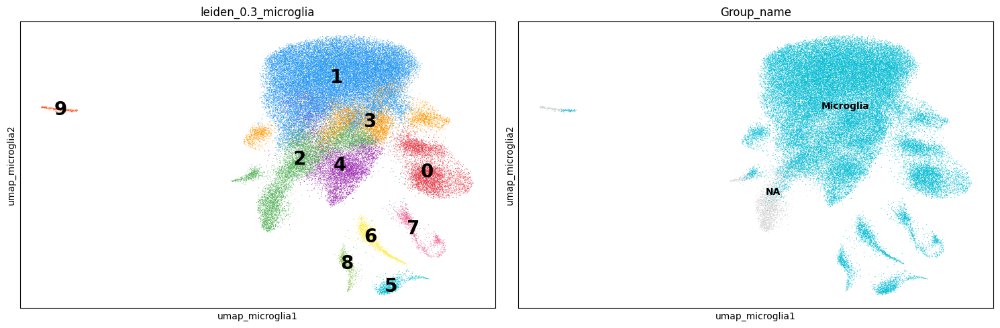

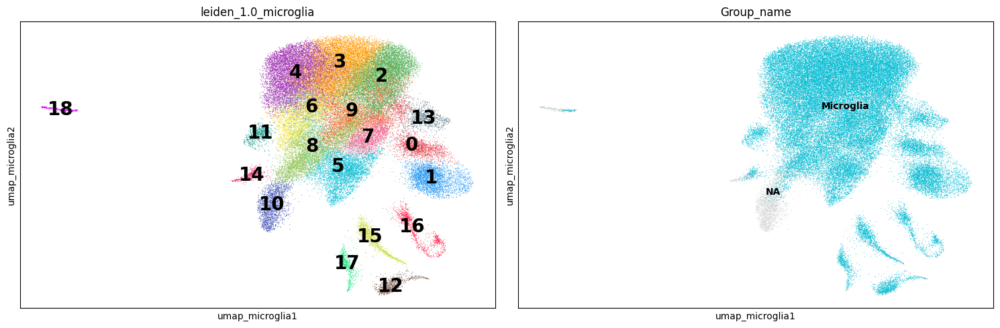

In [89]:
lmu.plot_to_decide(adata_nn, NAME, f"leiden_0.3{NAME}", GROUP_LABELS)
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Astrocyte                  121927
Oligodendrocyte            103003
Matrix_D1                   71001
Matrix_D2                   62107
-Low_quality                60733
Microglia                   35689
OPC                         30169
Patch_D1                    19034
Patch_D2                    14060
STR FS PTHLH-PVALB GABA     11572
STR TAC3 GABA                9972
eMSN_D1D2                    7344
-Activated_Microglia         5105
Ependymal                    4756
Fibroblasts                  3442
Endothelial_BBB              2729
STR SST-CHODL GABA           1991
Macrophages                  1969
VIP GABA                     1771
Pericytes                    1525
-Phase_D                     1518
Cholinergic GABA             1407
eMSN_StrioMat                1170
eMSN_NUDAP                   1152
-Cycling_Microglia            945
non-MSN                       881
COP                           742
Activated_Pericytes           739
ACx MEIS2 GABA                651
STR

... storing 'ct_for_deg' as categorical


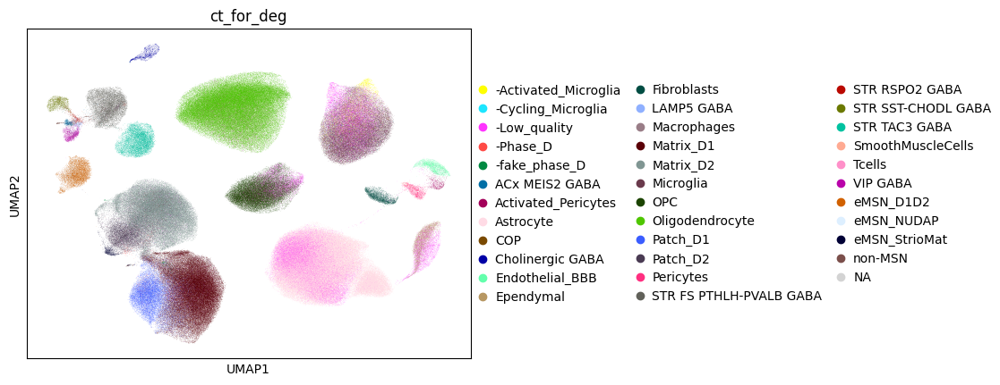

... storing 'tmp_label' as categorical


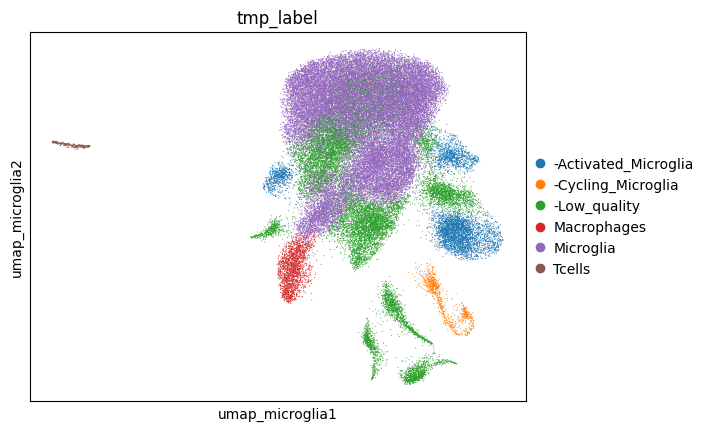

In [92]:
# map clusters to yout ct
mapping_dict = {

    "10": "Macrophages",
    "18": "Tcells",
    #"6": "Bcells",


    "1": "-Activated_Microglia",
    "13": "-Activated_Microglia",
    "11": "-Activated_Microglia",
    "16": "-Cycling_Microglia", # CENPP (centormere)


    "5": LOW_QUALITY_LABEL,  # mito
    "14": LOW_QUALITY_LABEL,  # mito
    "6": LOW_QUALITY_LABEL, #ribo
    "0": LOW_QUALITY_LABEL, #ribo
    "12": LOW_QUALITY_LABEL, #neruons LSAMP
    "15": LOW_QUALITY_LABEL, #oligo
    "17": LOW_QUALITY_LABEL, #neurons LSAMP, SLC1A2



    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("Microglia")

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Non-MSN Neurons

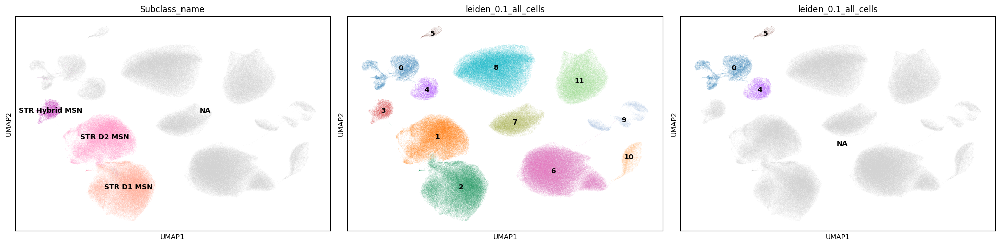

In [14]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["0", "4", "5"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["MSN"]
NAME="_neuroms"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-27 17:14:26,138 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-27 17:14:26 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-27 17:14:26,140 - harmonypy - INFO -   Parameters:
2026-08-27 17:14:26 | [INFO]   Parameters:
2026-08-27 17:14:26,141 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-27 17:14:26 | [INFO]     max_iter_harmony: 30
2026-08-27 17:14:26,141 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-27 17:14:26 | [INFO]     max_iter_kmeans: 20
2026-08-27 17:14:26,142 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-27 17:14:26 | [INFO]     epsilon_cluster: 1e-05
2026-08-27 17:14:26,143 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-27 17:14:26 | [INFO]     epsilon_harmony: 0.0001
2026-08-27 17:14:26,144 - harmonypy - INFO -     nclust: 100
2026-08-27 17:14:26 | [INFO]     nclust: 100
2026-08-27 17:14:26,145 - harmonypy - INFO -     block_size: 0.05
2026-08-27 17:14:26 | [INFO]     block_size: 0.05
2026-08-27 17:14:26,147 - harm

Running Harmony batch correction...


2026-08-27 17:14:27,269 - harmonypy - INFO - KMeans initialization complete.
2026-08-27 17:14:27 | [INFO] KMeans initialization complete.
2026-08-27 17:14:27,274 - harmonypy - INFO - Iteration 1 of 30
2026-08-27 17:14:27 | [INFO] Iteration 1 of 30
2026-08-27 17:14:29,620 - harmonypy - INFO - Iteration 2 of 30
2026-08-27 17:14:29 | [INFO] Iteration 2 of 30
2026-08-27 17:14:32,036 - harmonypy - INFO - Iteration 3 of 30
2026-08-27 17:14:32 | [INFO] Iteration 3 of 30
2026-08-27 17:14:34,615 - harmonypy - INFO - Iteration 4 of 30
2026-08-27 17:14:34 | [INFO] Iteration 4 of 30
2026-08-27 17:14:36,610 - harmonypy - INFO - Iteration 5 of 30
2026-08-27 17:14:36 | [INFO] Iteration 5 of 30
2026-08-27 17:14:38,325 - harmonypy - INFO - Iteration 6 of 30
2026-08-27 17:14:38 | [INFO] Iteration 6 of 30
2026-08-27 17:14:40,169 - harmonypy - INFO - Iteration 7 of 30
2026-08-27 17:14:40 | [INFO] Iteration 7 of 30
2026-08-27 17:14:41,868 - harmonypy - INFO - Iteration 8 of 30
2026-08-27 17:14:41 | [INFO] 

Z_corr shape: (29132, 50), n_obs: 29132
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


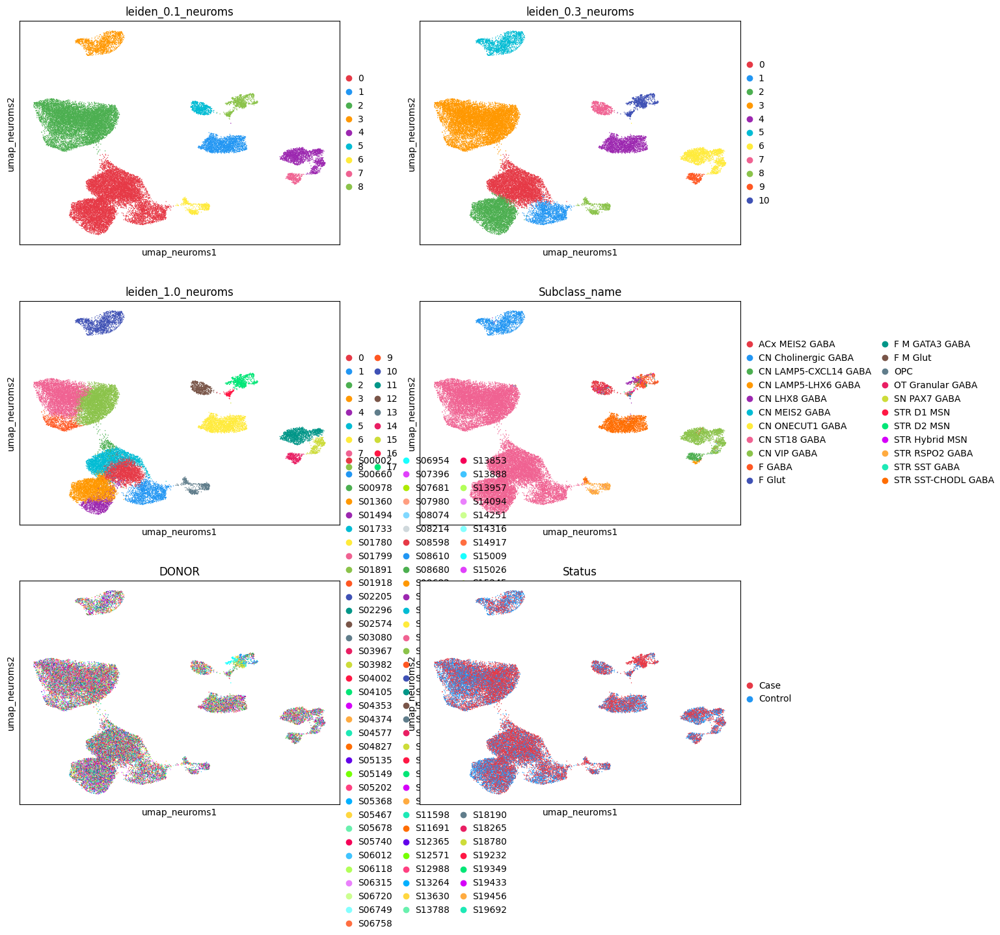

In [15]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

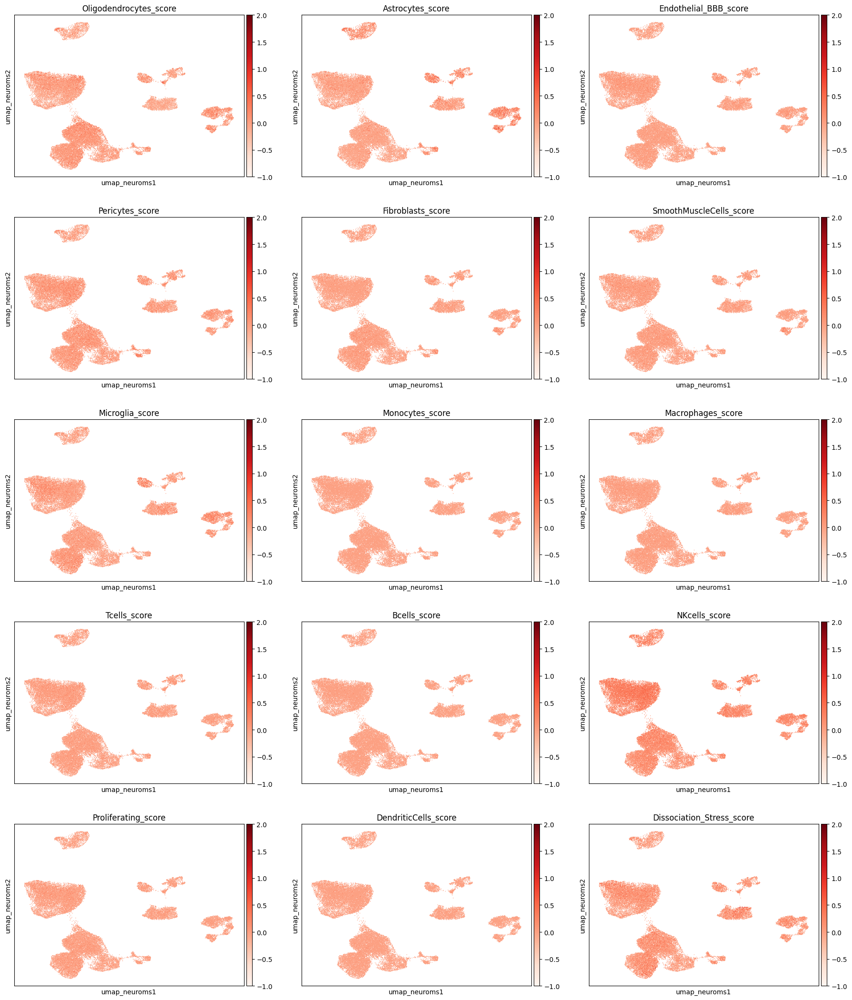

In [26]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


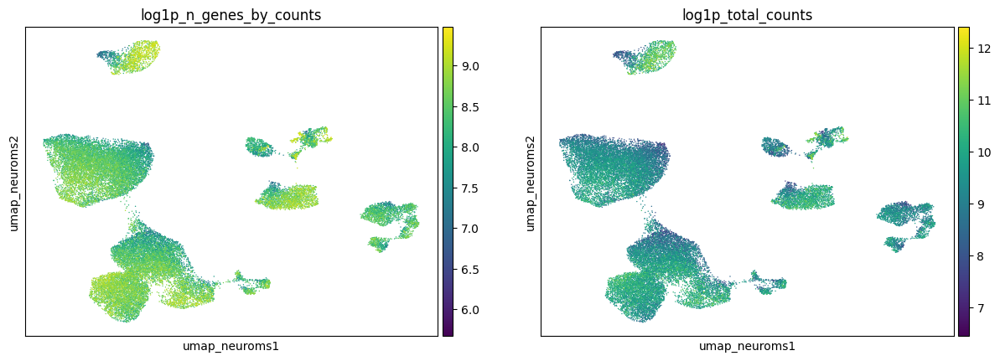

In [17]:

sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts"], legend_loc="on data")

In [20]:

ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"

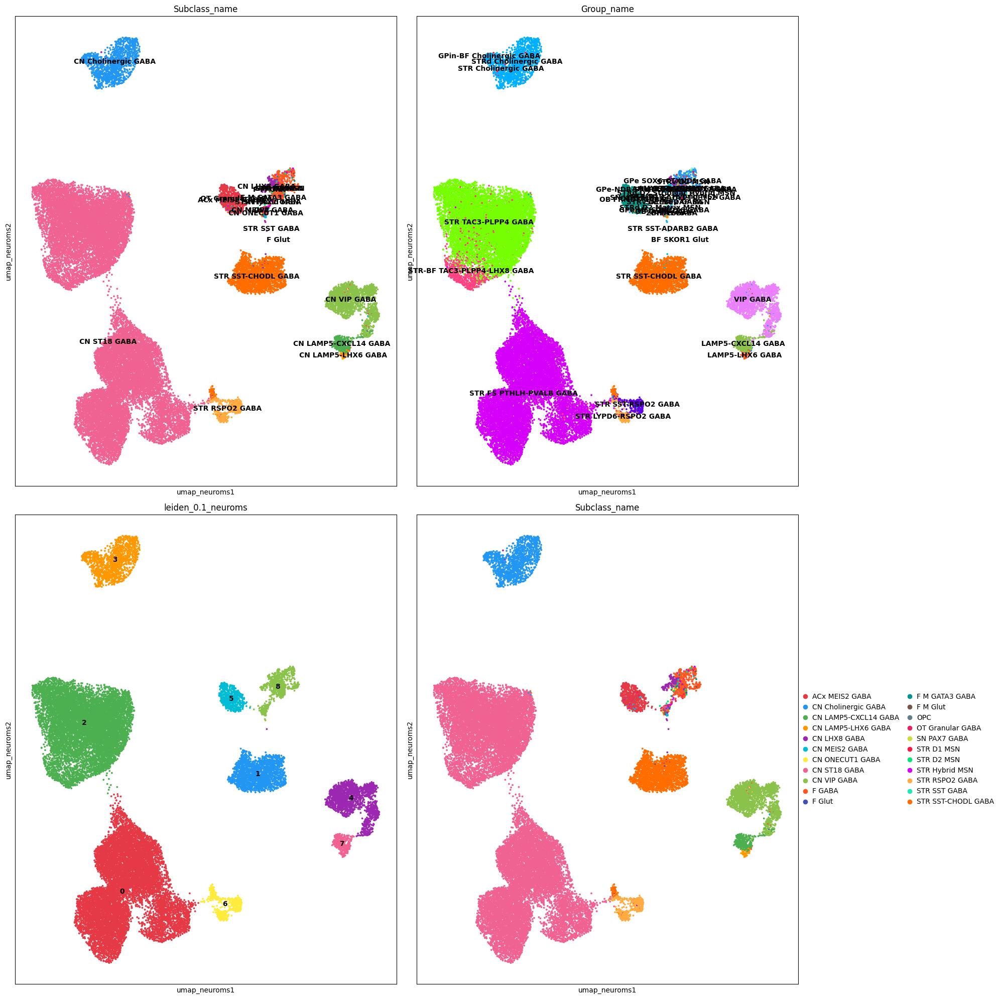

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
axes = axes.flatten()
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], legend_loc="on data", ax=axes[0], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], legend_loc="on data", ax=axes[1], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ADATA_NN_LEIDEN_COL_FOR_MAPPING], legend_loc="on data", ax=axes[2], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], ax=axes[3], show=False, size=30, palette=lmu.custom_palette)
plt.tight_layout(); plt.show()

In [27]:
adata_nn.obs[adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING] == "5"]["Subclass_name"].value_counts()

Subclass_name
ACx MEIS2 GABA          492
OT Granular GABA         65
CN MEIS2 GABA            32
F GABA                   29
STR Hybrid MSN           28
F M GATA3 GABA            2
STR D2 MSN                2
CN ST18 GABA              1
CN LAMP5-CXCL14 GABA      0
CN Cholinergic GABA       0
CN LHX8 GABA              0
CN LAMP5-LHX6 GABA        0
CN VIP GABA               0
CN ONECUT1 GABA           0
OPC                       0
F M Glut                  0
F Glut                    0
SN PAX7 GABA              0
STR D1 MSN                0
STR RSPO2 GABA            0
STR SST GABA              0
STR SST-CHODL GABA        0
Name: count, dtype: int64

### Final decision

ALL non-msn

remove oligo_cotamination

ct_for_deg
STR FS PTHLH-PVALB GABA    11572
STR TAC3 GABA               9972
STR SST-CHODL GABA          1991
VIP GABA                    1771
Cholinergic GABA            1407
non-MSN                      881
ACx MEIS2 GABA               651
STR RSPO2 GABA               530
LAMP5 GABA                   357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


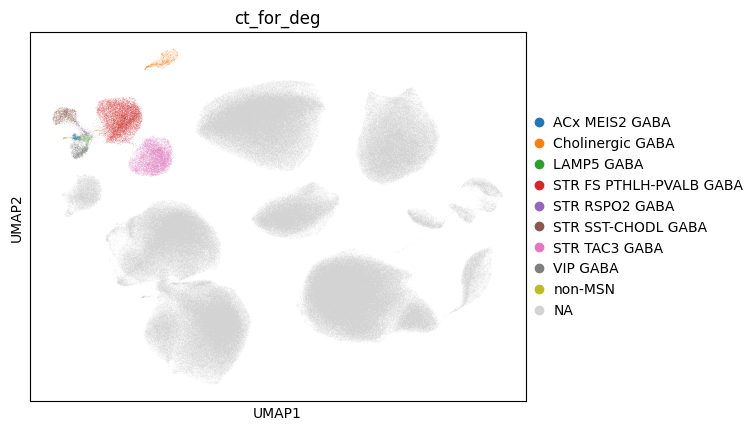

... storing 'tmp_label' as categorical


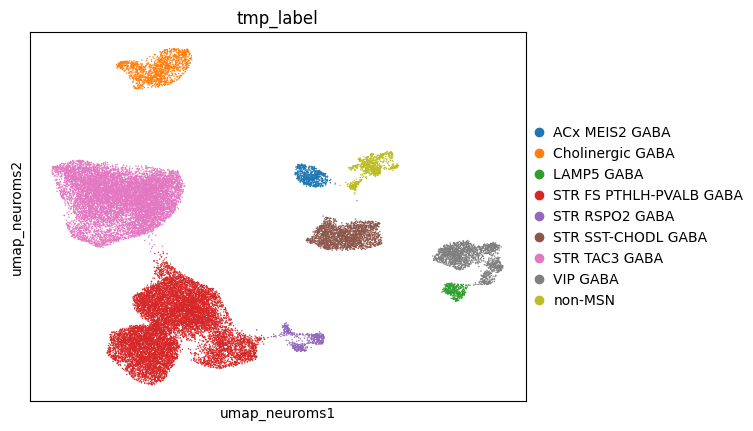

In [28]:
# map clusters to yout ct
mapping_dict = {
 
    # "7": LOW_QUALITY_LABEL, 


    "3": "Cholinergic GABA",# subclass lsveel
    "4": "VIP GABA",  #group lsveel
    "7": "LAMP5 GABA", # 2 merged
    "1": "STR SST-CHODL GABA", # subclass lsveel
    "6": "STR RSPO2 GABA", # subclass lsveel
    "0":  "STR FS PTHLH-PVALB GABA", #GORUP
    "2": "STR TAC3 GABA", #MERGED: grup
    "5": "ACx MEIS2 GABA" #subclass


    # MSN all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("non-MSN")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [ ]:
del adata_nn

# MSN all (hybrdids and non)

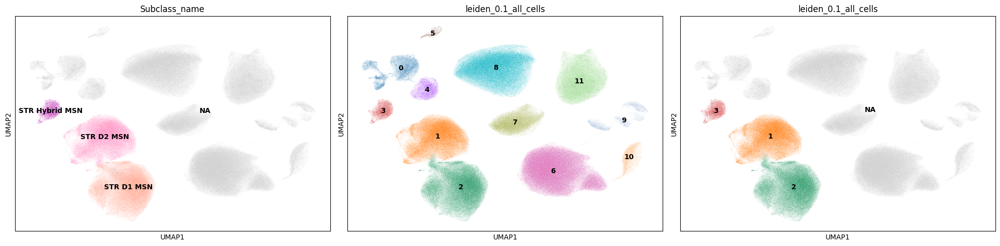

In [5]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["1", "2", "3"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["MSN"]
NAME="_MSN"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-08-27 19:52:52,018 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-08-27 19:52:52 | [INFO] Running Harmony (PyTorch on cuda)
2026-08-27 19:52:52,020 - harmonypy - INFO -   Parameters:
2026-08-27 19:52:52 | [INFO]   Parameters:
2026-08-27 19:52:52,021 - harmonypy - INFO -     max_iter_harmony: 30
2026-08-27 19:52:52 | [INFO]     max_iter_harmony: 30
2026-08-27 19:52:52,022 - harmonypy - INFO -     max_iter_kmeans: 20
2026-08-27 19:52:52 | [INFO]     max_iter_kmeans: 20
2026-08-27 19:52:52,023 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-08-27 19:52:52 | [INFO]     epsilon_cluster: 1e-05
2026-08-27 19:52:52,023 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-08-27 19:52:52 | [INFO]     epsilon_harmony: 0.0001
2026-08-27 19:52:52,024 - harmonypy - INFO -     nclust: 100
2026-08-27 19:52:52 | [INFO]     nclust: 100
2026-08-27 19:52:52,025 - harmonypy - INFO -     block_size: 0.05
2026-08-27 19:52:52 | [INFO]     block_size: 0.05
2026-08-27 19:52:52,027 - harm

Running Harmony batch correction...


2026-08-27 19:52:52,574 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-27 19:52:52 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-08-27 19:52:56,297 - harmonypy - INFO - KMeans initialization complete.
2026-08-27 19:52:56 | [INFO] KMeans initialization complete.
2026-08-27 19:52:56,479 - harmonypy - INFO - Iteration 1 of 30
2026-08-27 19:52:56 | [INFO] Iteration 1 of 30
2026-08-27 19:52:59,594 - harmonypy - INFO - Iteration 2 of 30
2026-08-27 19:52:59 | [INFO] Iteration 2 of 30
2026-08-27 19:53:02,632 - harmonypy - INFO - Iteration 3 of 30
2026-08-27 19:53:02 | [INFO] Iteration 3 of 30
2026-08-27 19:53:05,412 - harmonypy - INFO - Converged after 3 iterations
2026-08-27 19:53:05 | [INFO] Converged after 3 iterations


Z_corr shape: (181099, 50), n_obs: 181099
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


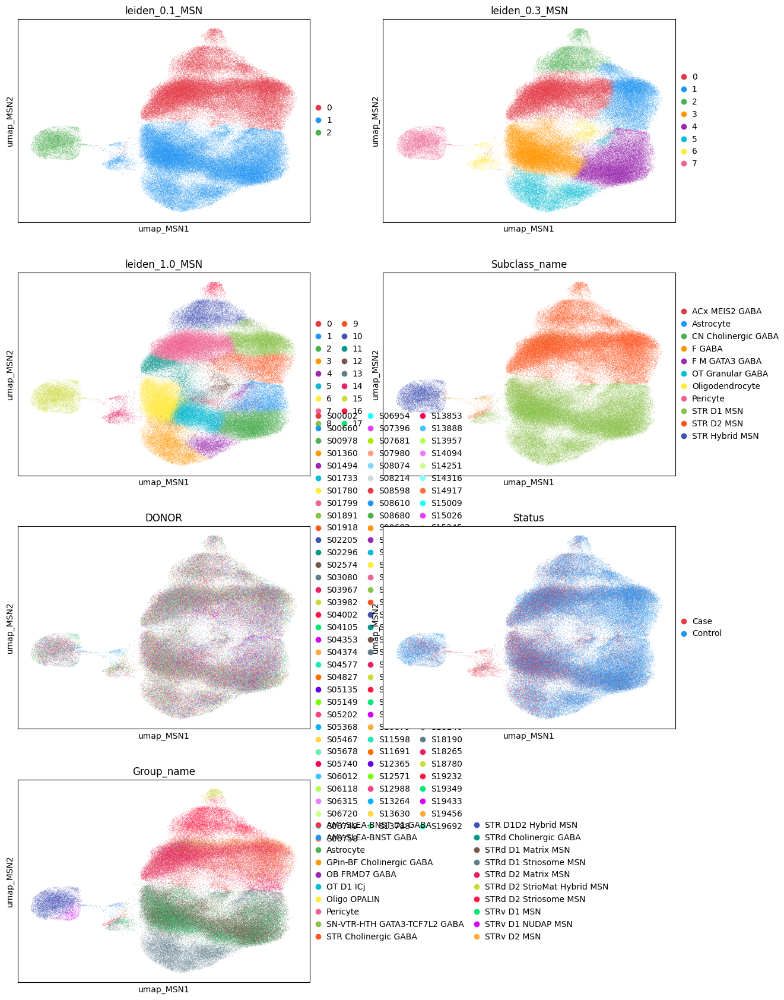

In [6]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE, "Group_name"], ncols=2, palette=preprocessing.custom_palette)



... storing 'MSN_type' as categorical


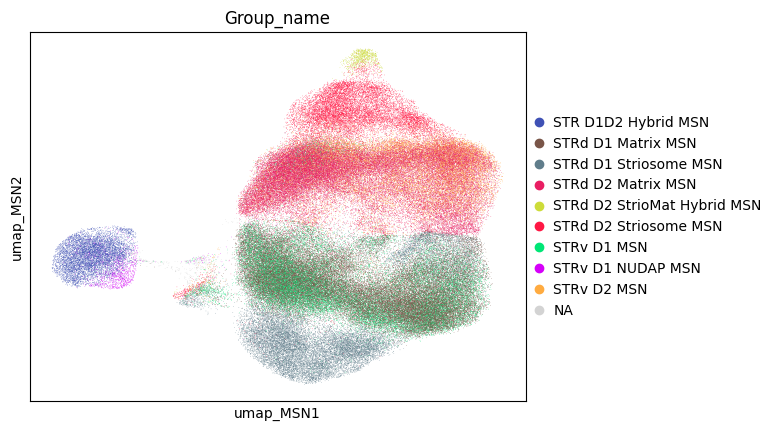

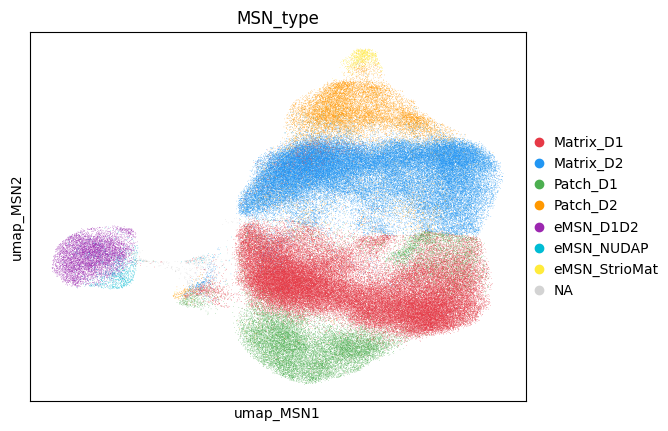

In [12]:
# map Group-name to broader categories
mapping_msn = {
    "STRd D1 Matrix MSN": "Matrix_D1",
    "STRd D2 Matrix MSN": "Matrix_D2",
    "STRv D1 MSN": "Matrix_D1",
    "STRv D2 MSN": "Matrix_D2",

    "STRd D2 Striosome MSN": "Patch_D2",
    "STRd D1 Striosome MSN": "Patch_D1",

    "STRd D2 StrioMat Hybrid MSN": "eMSN_StrioMat",
    "STR D1D2 Hybrid MSN": "eMSN_D1D2",
    "STRv D1 NUDAP MSN": "eMSN_NUDAP"
  }
adata_nn.obs["MSN_type"] = adata_nn.obs["Group_name"].map(mapping_msn)

ct_to_color = list(mapping_msn.keys())
ct_to_color

sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=ct_to_color, ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette)


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

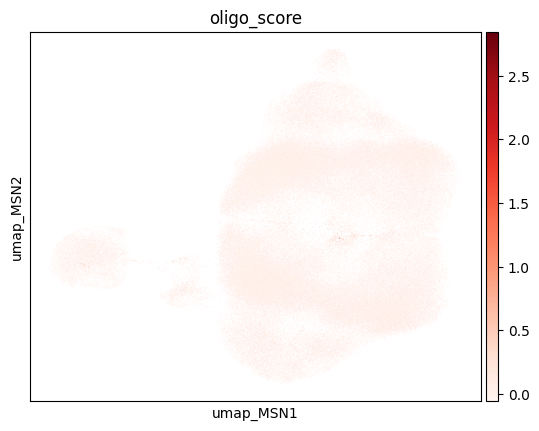

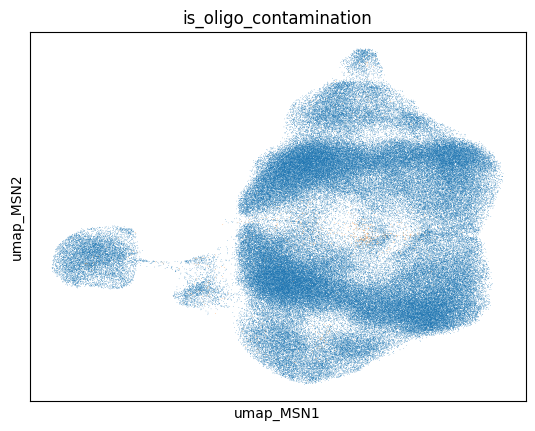

In [8]:
# Check if they are ooligos contamiantion
dict_oligo={"oligo": ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"]}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_nn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}")
adata_nn.obs["is_oligo_contamination"] = (adata_nn.obs[col_oligo_score[0]] >= 0.25).fillna(0).astype(bool)
#adata_nn.obs[col_oligo_score[0]].plot(kind="hist", bins=100)
sc.pl.embedding(adata_nn, color="is_oligo_contamination", basis=f"umap{NAME}", ncols=5, legend_loc=None)


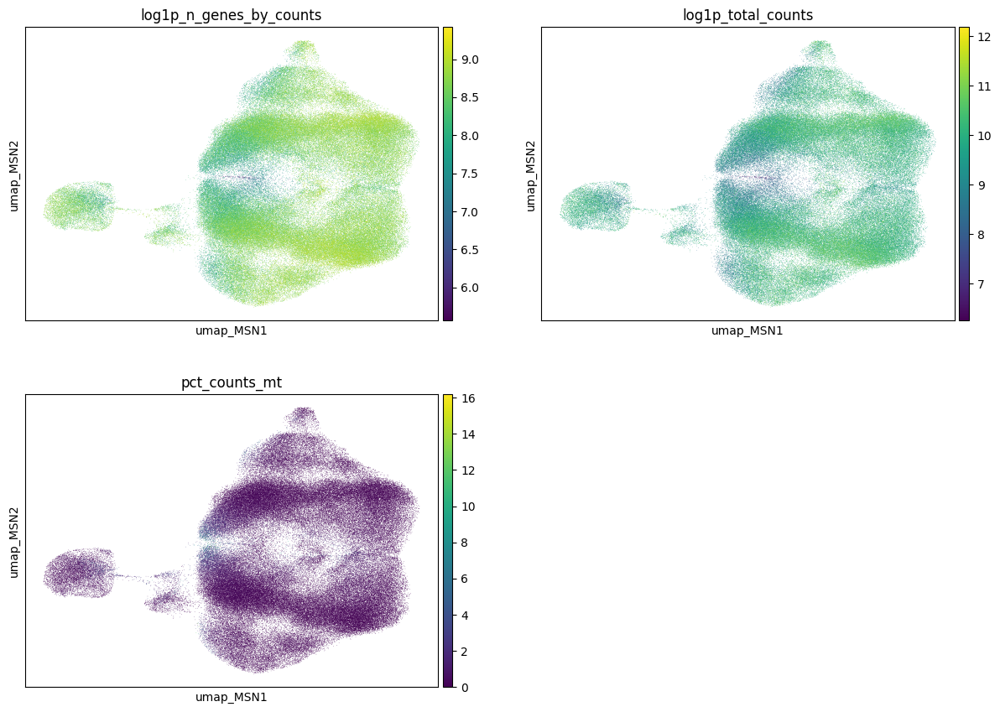

In [9]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"], legend_loc="on data", ncols=2)

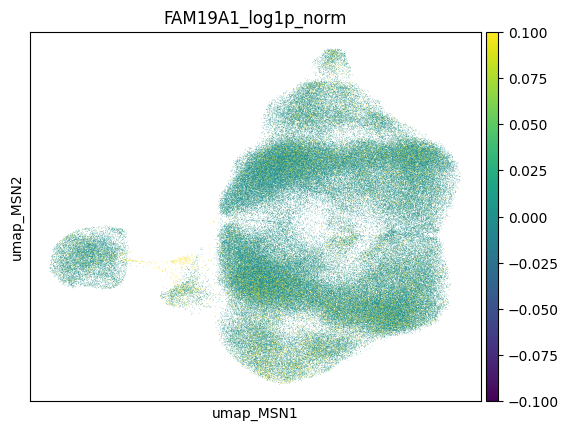

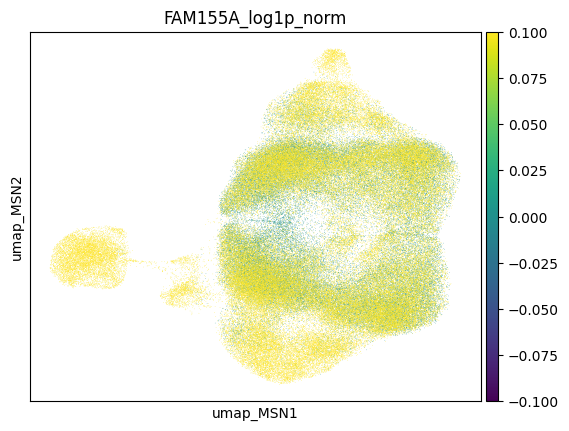

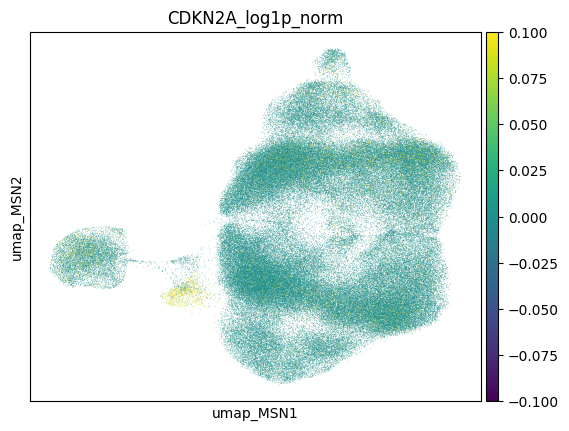

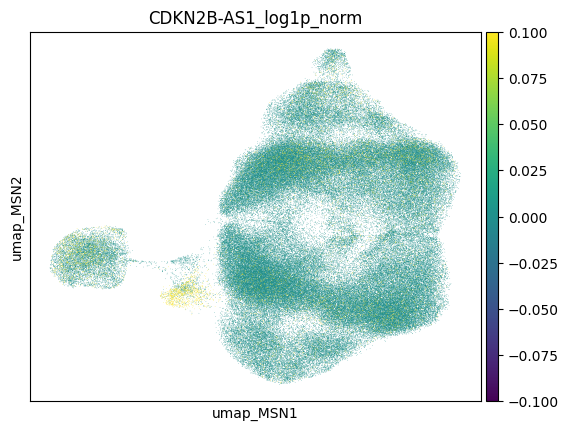

In [10]:
# TAFA1

for gene in ["FAM19A1", "FAM155A", "CDKN2A", "CDKN2B-AS1"]: 
    idx_tafa1 = adata_nn.var.index.get_indexer(adata_nn.var.query(f"gene_symbol == '{gene}'").index)
    adata_nn.obs[f"{gene}_log1p_norm"] = adata_nn.layers["log1p_norm"][:, idx_tafa1].toarray().ravel()
    sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[f"{gene}_log1p_norm"], ncols=2, vmax=np.quantile(adata_nn.obs[f"{gene}_log1p_norm"].values, 0.2))
    plt.show()

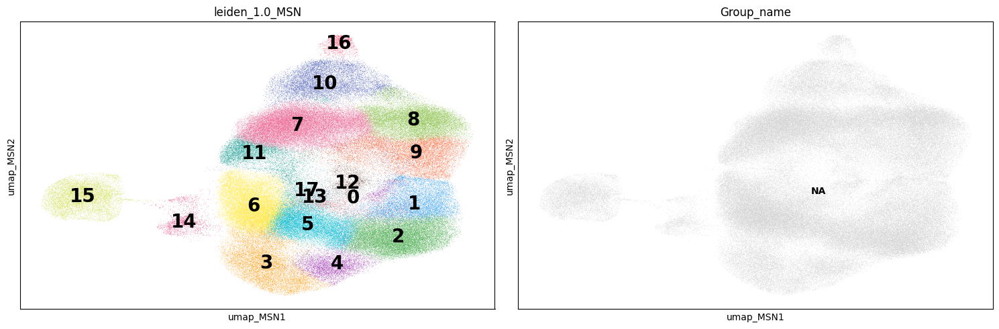

In [13]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = "leiden_1.0_MSN"
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

In [ ]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             groups=["12", "14"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 12:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000204442,56.587677,2.674524,0.000000e+00,0.000000e+00,FAM155A
1,ENSG00000187391,51.910046,0.926627,0.000000e+00,0.000000e+00,MAGI2
2,ENSG00000153707,46.942326,0.981449,0.000000e+00,0.000000e+00,PTPRD
3,ENSG00000139154,42.709194,1.077001,0.000000e+00,0.000000e+00,AEBP2
4,ENSG00000048052,41.985886,2.280835,0.000000e+00,0.000000e+00,HDAC9
5,ENSG00000018236,41.438869,0.697081,0.000000e+00,0.000000e+00,CNTN1
6,ENSG00000109339,41.250500,0.705741,0.000000e+00,0.000000e+00,MAPK10
7,ENSG00000226380,39.037697,1.254371,0.000000e+00,0.000000e+00,AC016831.1
8,ENSG00000230590,38.896862,0.486475,0.000000e+00,0.000000e+00,FTX
9,ENSG00000005020,38.449825,2.650687,0.000000e+00,0.000000e+00,SKAP2


Cluster 14:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000245532,57.031513,4.406929,0.000000e+00,0.000000e+00,NEAT1
1,ENSG00000162599,46.250648,1.893750,0.000000e+00,0.000000e+00,NFIA
2,ENSG00000101542,44.567261,4.707282,0.000000e+00,0.000000e+00,CDH20
3,ENSG00000112531,42.959232,1.118212,0.000000e+00,0.000000e+00,QKI
4,ENSG00000184384,41.837055,2.880303,0.000000e+00,0.000000e+00,MAML2
5,ENSG00000183580,41.044064,2.388140,0.000000e+00,0.000000e+00,FBXL7
6,ENSG00000196628,39.222980,4.167466,0.000000e+00,0.000000e+00,TCF4
7,ENSG00000107249,34.660305,2.643989,3.124698e-263,1.442947e-259,GLIS3
8,ENSG00000109458,33.874245,2.256003,1.595709e-251,6.550032e-248,GAB1
9,ENSG00000164199,32.499043,1.437460,1.099967e-231,4.063608e-228,ADGRV1


ct_for_deg
Matrix_D1                  71001
Matrix_D2                  62107
Patch_D1                   19034
Patch_D2                   14060
STR FS PTHLH-PVALB GABA    11572
STR TAC3 GABA               9972
eMSN_D1D2                   7344
-Low_quality                2848
-Phase_D                    2031
STR SST-CHODL GABA          1991
VIP GABA                    1771
Cholinergic GABA            1407
eMSN_StrioMat               1170
eMSN_NUDAP                  1152
non-MSN                      881
ACx MEIS2 GABA               651
STR RSPO2 GABA               530
LAMP5 GABA                   357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


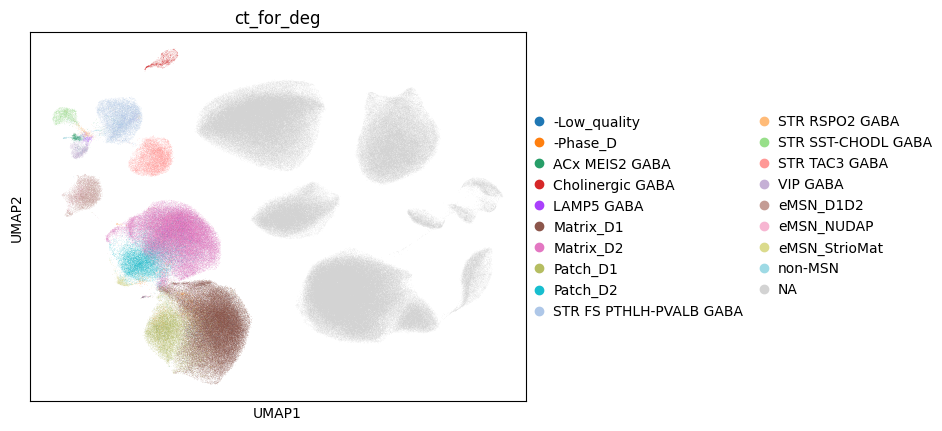

... storing 'tmp_label' as categorical


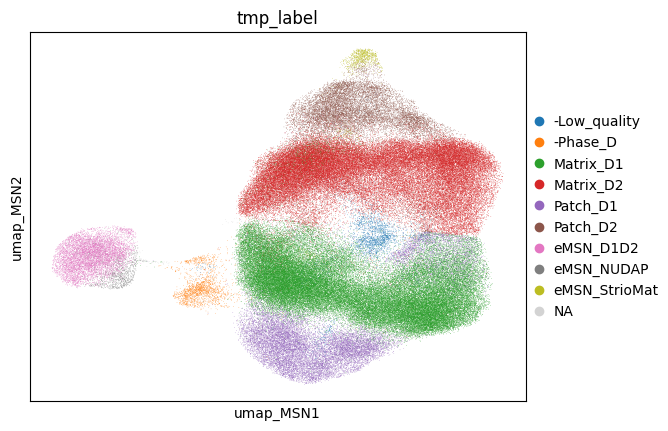

In [14]:
# map clusters to yout ct
mapping_dict = {

    "17": "eMSN_StrioMat",


    #"16": "EMNS_D1D2_NUDAP",


    "14": "-Phase_D",
    "12": LOW_QUALITY_LABEL, 

    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(adata_nn.obs["MSN_type"])

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Recluster PhaseD

In [5]:
adata_nn = adata[adata.obs["ct_for_deg"] == "-Phase_D"].copy()
adata_nn

AnnData object with n_obs × n_vars = 2031 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone_

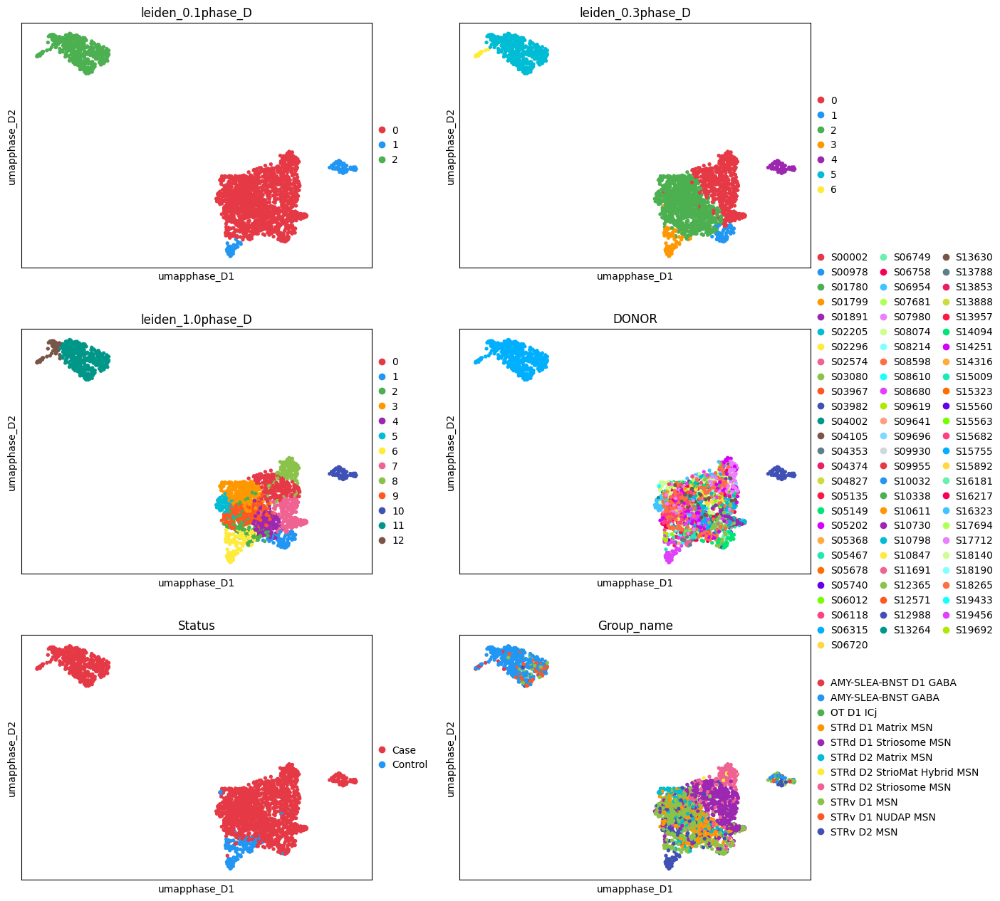

In [7]:
# NAME="phase_D"

# #remov elow vianerc egenes
# sc.pp.filter_genes(adata_nn, min_cells=3)


# # rerun analsys
# leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=False, batch_key=None)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, SAMPLE_VARIABLE, CONDITION_VARIABLE, "Group_name"], ncols=2, palette=preprocessing.custom_palette)



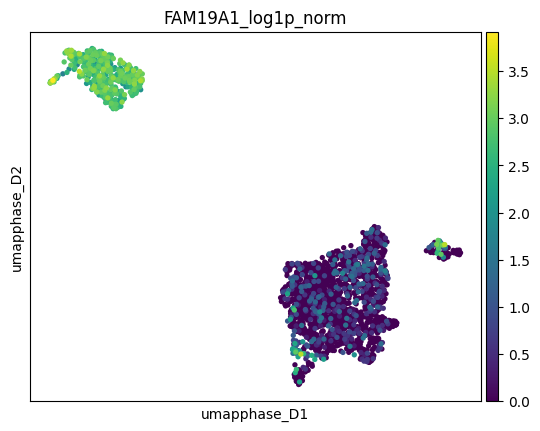

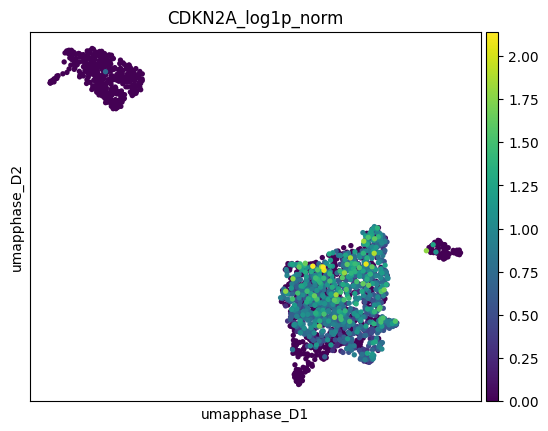

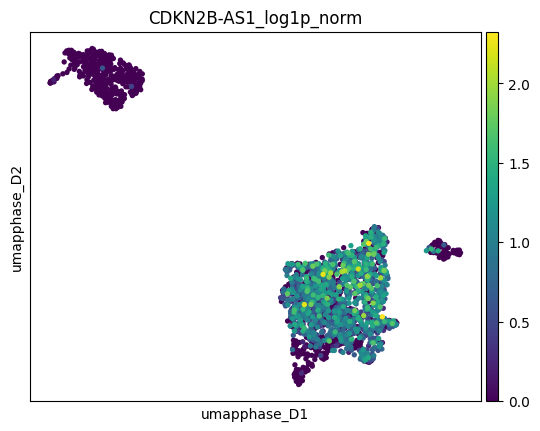

In [23]:
# TAFA1

for gene in ["FAM19A1", "CDKN2A", "CDKN2B-AS1"]: 
    idx_tafa1 = adata_nn.var.index.get_indexer(adata_nn.var.query(f"gene_symbol == '{gene}'").index)
    adata_nn.obs[f"{gene}_log1p_norm"] = adata_nn.layers["log1p_norm"][:, idx_tafa1].toarray().ravel()
    sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[f"{gene}_log1p_norm"], ncols=2,)
    plt.show()

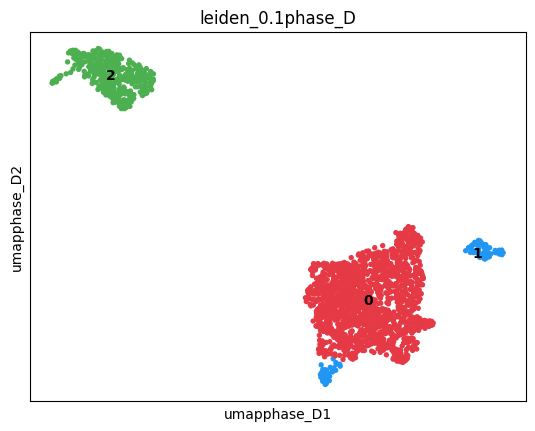

In [19]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=ADATA_NN_LEIDEN_COL_FOR_MAPPING, legend_loc="on data")

In [20]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             #groups=["12", "14"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000114541,31.344845,4.685495,1.143722e-215,7.891397e-212,FRMD4B
1,ENSG00000112541,31.191187,3.779583,1.402997e-213,7.744261e-210,PDE10A
2,ENSG00000276644,30.862535,3.979414,3.803328e-209,1.749467e-205,DACH1
3,ENSG00000164741,30.815771,4.064872,1.611163e-208,6.352354e-205,DLC1
4,ENSG00000271860,30.199919,3.463762,2.374392e-200,6.907376e-197,AL589740.1
5,ENSG00000174948,29.336010,4.433596,3.604065e-189,6.631239e-186,GPR149
6,ENSG00000196104,29.177563,3.724202,3.735827e-187,6.444069e-184,SPOCK3
7,ENSG00000137942,28.729912,3.236814,1.614545e-181,2.121896e-178,FNBP1L
8,ENSG00000179399,28.722248,4.208992,2.012658e-181,2.524879e-178,GPC5
9,ENSG00000178568,28.461216,3.950856,3.540115e-178,3.757832e-175,ERBB4


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000156687,14.391674,3.531963,5.836567e-47,8.209830e-43,UNC5D
1,ENSG00000112902,14.232205,5.040973,5.782899e-46,3.990056e-42,SEMA5A
2,ENSG00000156299,13.806414,1.505103,2.331549e-43,1.286969e-39,TIAM1
3,ENSG00000047648,13.511671,3.274280,1.334565e-41,6.138777e-38,ARHGAP6
4,ENSG00000169855,13.351310,1.250982,1.163851e-40,4.015139e-37,ROBO1
5,ENSG00000145416,13.152785,1.540008,1.640199e-39,4.895914e-36,MARCH1
6,ENSG00000155511,13.146857,1.149119,1.773946e-39,4.895914e-36,GRIA1
7,ENSG00000185053,12.721959,2.050801,4.465244e-37,8.802590e-34,SGCZ
8,ENSG00000179603,12.610395,2.580169,1.850622e-36,3.405020e-33,GRM8
9,ENSG00000185532,12.430790,2.093881,1.778683e-35,3.068117e-32,PRKG1


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000144868,30.833424,6.449031,9.345064e-209,2.579144e-204,TMEM108
1,ENSG00000196628,30.549252,5.398790,5.785678e-205,5.005877e-201,TCF4
2,ENSG00000171617,30.548630,4.941159,5.896565e-205,5.005877e-201,ENC1
3,ENSG00000070808,30.541849,3.083631,7.255157e-205,5.005877e-201,CAMK2A
4,ENSG00000146147,30.529625,8.234372,1.054231e-204,5.819147e-201,MLIP
5,ENSG00000154975,30.509283,7.825560,1.962689e-204,9.028044e-201,CA10
6,ENSG00000152578,30.464586,4.991216,7.678475e-204,3.027403e-200,GRIA4
7,ENSG00000216863,30.439945,10.155050,1.627409e-203,5.614359e-200,LY86-AS1
8,ENSG00000183662,30.409386,5.874322,4.128070e-203,1.265896e-199,FAM19A1
9,ENSG00000147862,30.347307,5.680973,2.726673e-202,6.841222e-199,NFIB


ct_for_deg
Matrix_D1                  71001
Matrix_D2                  62107
Patch_D1                   19034
Patch_D2                   14060
STR FS PTHLH-PVALB GABA    11572
STR TAC3 GABA               9972
eMSN_D1D2                   7344
-Low_quality                2848
STR SST-CHODL GABA          1991
VIP GABA                    1771
-Phase_D                    1518
Cholinergic GABA            1407
eMSN_StrioMat               1170
eMSN_NUDAP                  1152
non-MSN                      881
ACx MEIS2 GABA               651
STR RSPO2 GABA               530
-fake_phase_D                513
LAMP5 GABA                   357
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


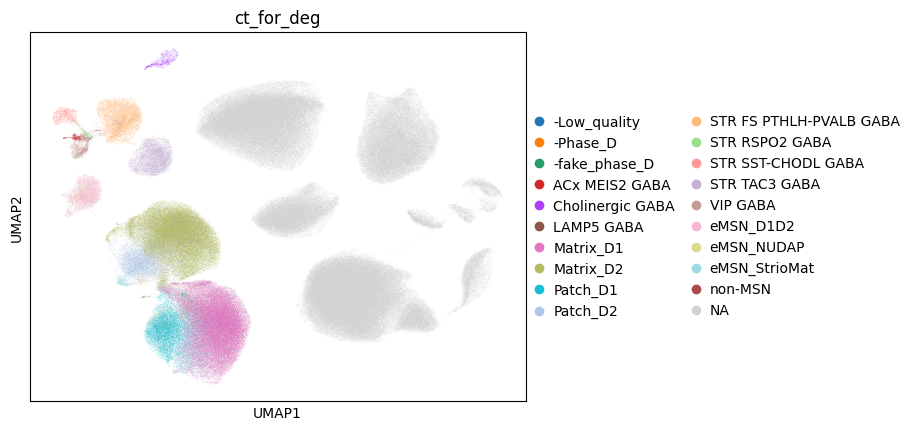

... storing 'tmp_label' as categorical


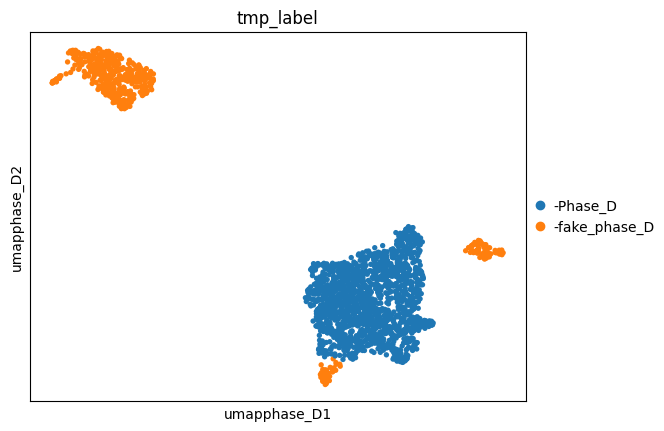

In [24]:
# map clusters to yout ct
mapping_dict = {


    "0": "-Phase_D",
    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("-fake_phase_D")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# All rest

352


... storing 'ct_for_deg' as categorical


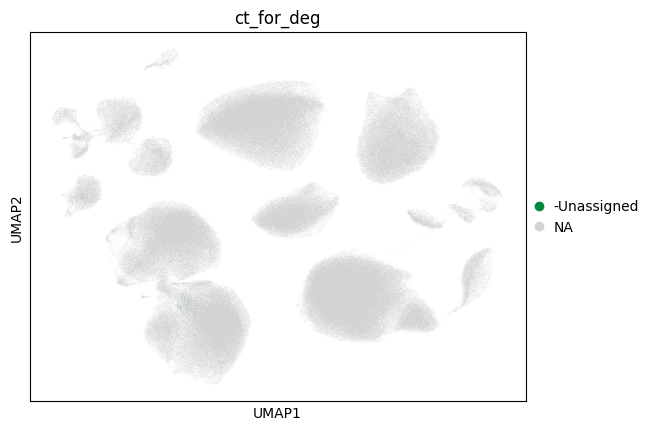

In [94]:
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].fillna("-Unassigned")

print(adata.obs["ct_for_deg"].value_counts().loc["-Unassigned"])

sc.pl.umap(adata, color="ct_for_deg", groups=["-Unassigned"])

# "is neuron"

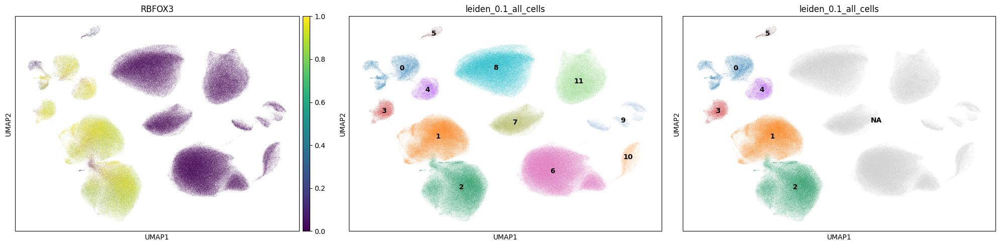

In [98]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["0", "1", "2", "3", "4", "5"]
MMC_ANNOTATION_LEVEL = "Subclass_name"

# to help  picking clusters
fig, ax = plt.subplots(1, 3, figsize=(20,5))
sc.pl.umap(adata, color="RBFOX3", gene_symbols="gene_symbol", ax=ax[0], show=False, legend_loc="on data", layer="log1p_norm", vmax=1)
sc.pl.umap(adata, color=CLUSTERS_ALL_CELLS_COL, ax=ax[1], show=False, legend_loc="on data")
sc.pl.umap(adata, color=CLUSTERS_ALL_CELLS_COL, groups=CLUSTERS_GROUP_ALL_CELLS, ax=ax[2], show=False, legend_loc="on data")
plt.tight_layout(); plt.show()

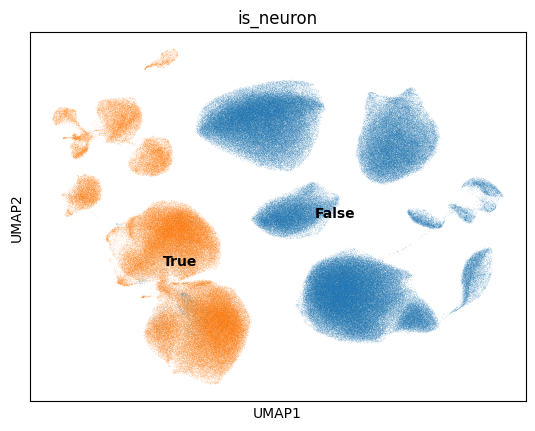

In [99]:
adata.obs["is_neuron"] = adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS) & (~adata.obs["ct_for_deg"].str.startswith("-"))
sc.pl.umap(adata, color="is_neuron", legend_loc="on data")


# Save

In [2]:
SAVE_PATH =  f'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad'
print(SAVE_PATH)
#print(adata)

/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad


In [100]:
adata.write_h5ad(SAVE_PATH)

/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


# Reload

In [3]:
adata = sc.read_h5ad(SAVE_PATH)#, backed="r")

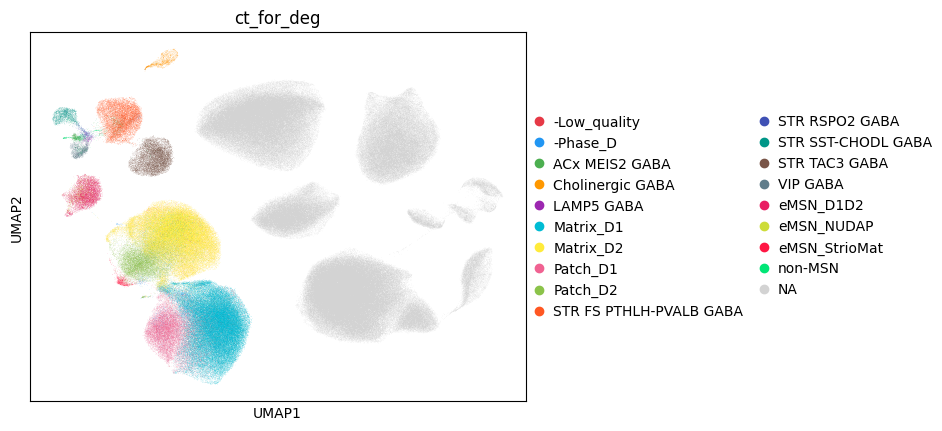

In [6]:
sc.pl.umap(adata, color="ct_for_deg", palette=preprocessing.custom_palette)

# ---

In [ ]:
for ct, group, zone_col in [
        ("Matrix_D1", ["STRd D1 Matrix MSN", "STRv D1 MSN"], "zone"), 
        ("Matrix_D2", ["STRd D2 Matrix MSN", "STRv D2 MSN"], "zone"), 
        ("Patch_D1", ["STRd D1 Striosome MSN"], "zone_4"), 
        ("Patch_D2", ["STRd D2 Striosome MSN"], "zone_4"), 
        ("eMSN_D1D2", ["STR D1D2 Hybrid MSN"], "zone_4"), 
        ("Astrocyte", ["Astrocyte"], "zone_4"), 
    ]:

    print(ct, group)

    mask_group = adata.obs["Group_name"].isin(group)

    adata_sub = adata[mask_group].copy()
    adata_sub_village = adata_sub[adata_sub.obs["experiment"] == "village"].copy()
    display(adata_sub)
    display(adata.obs[zone_col].value_counts())


    fig, axis = plt.subplots(1,2, figsize=(12,6))
    sns.countplot(data=adata_sub.obs, x=zone_col, hue=CONDITION_VARIABLE, ax=axis[0]); axis[0].set_title(ct)
    sns.countplot(data=adata_sub_village.obs, x=zone_col, hue=CONDITION_VARIABLE, ax=axis[1]); axis[1].set_title("Only Village")
    plt.show()


    # lmu.preprocess_common_pipeline(adata_sub, umap_name=f"_check_{ct}", leiden_name=f"_check_{ct}", resolutions = [0.1], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)
    # sc.pl.embedding(adata_sub, basis=f"umap_check_{ct}", color=["Group_name", "ct_for_deg", zone_col, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)

# Compare Matrix D1 Matthew

In [ ]:
adata.obs["village"] = np.where(adata.obs["experiment"] == "village", adata.obs["reaction"].str.split("_").str[0], np.nan)


display(adata.obs[adata.obs["experiment"] =="village"]["village"].value_counts().head(10))
display(adata.obs[adata.obs["experiment"] =="deepdive"]["DONOR"].value_counts().head(9))
display(adata.obs[adata.obs["experiment"] =="village"]["DONOR"].nunique())

In [ ]:
d1d2_mat = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/from_matthew/STR_D1D2_Hybrid_MSN.h5ad")
print(d1d2_mat)

d1d2 = adata[adata.obs["Group_name"].isin(["STR D1D2 Hybrid MSN"])].copy()
display(d1d2)

In [ ]:
md1_mat = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/from_matthew/STR_D1_Matrix_MSN.h5ad")
print(md1_mat)

md1 = adata[adata.obs["Group_name"].isin(["STRd D1 Matrix MSN", "STRv D1 MSN"])].copy()
print(md1)
md1.obs["is_deepdive"].value_counts()

In [ ]:
display(md1_mat.obs)
display(md1.obs)

display(md1.obs[md1.obs["CELL_BARCODE"].isin(set(md1.obs["CELL_BARCODE"]).difference(set(md1_mat.obs["CELL_BARCODE"])))])
display(md1.obs[md1.obs["reaction"].isin(set(md1.obs["reaction"]).difference(set(md1_mat.obs["reaction"])))])